In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
with open("Swiggy_Chennai.csv", "r", encoding="utf-8-sig") as file:
    for i in range(5):
        print(repr(file.readline()))

'ID\tArea\tCity\tRestaurant\tPrice\tAvg ratings\tTotal ratings\tFood type\tAddress\tDelivery time\n'
'6345\tTeynampet\tChennai\tAmaravathi\t650\t4.2\t100\t"Indian,Chinese,Andhra,Tandoor"\tCathedral Road\t53\n'
'6358\tNandanam\tChennai\tEatalica\t500\t4.5\t100\t"Italian,American"\tRa Puram\t69\n'
'7776\tGopalapuram\tChennai\tThe Kati Roll Shop\t250\t4.3\t1000\tStreet Food\tCathedral Road\t52\n'
'7826\tAlwarpet\tChennai\tBenjarong\t1500\t4.6\t100\tThai\tTtk Road\t68\n'


In [4]:
df = pd.read_csv("Swiggy_Chennai.csv", sep="\t")

In [5]:
df.head()

,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,6345,Teynampet,Chennai,Amaravathi,650,4.2,100,"Indian,Chinese,Andhra,Tandoor",Cathedral Road,53
1,6358,Nandanam,Chennai,Eatalica,500,4.5,100,"Italian,American",Ra Puram,69
2,7776,Gopalapuram,Chennai,The Kati Roll Shop,250,4.3,1000,Street Food,Cathedral Road,52
3,7826,Alwarpet,Chennai,Benjarong,1500,4.6,100,Thai,Ttk Road,68
4,7828,Mylapore,Chennai,Kaaraikudi,500,3.6,100,Chettinad,Dr Radhakrishnan Salai,57


In [7]:
df.shape

(1106, 10)

In [8]:
df.columns

Index(['ID', 'Area', 'City', 'Restaurant', 'Price', 'Avg ratings',
       'Total ratings', 'Food type', 'Address', 'Delivery time'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1106 entries, 0 to 1105
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             1106 non-null   int64  
 1   Area           1106 non-null   str    
 2   City           1106 non-null   str    
 3   Restaurant     1106 non-null   str    
 4   Price          1106 non-null   int64  
 5   Avg ratings    1106 non-null   float64
 6   Total ratings  1106 non-null   int64  
 7   Food type      1106 non-null   str    
 8   Address        1106 non-null   str    
 9   Delivery time  1106 non-null   int64  
dtypes: float64(1), int64(4), str(5)
memory usage: 86.5 KB


In [11]:
df.isnull().sum()

ID               0
Area             0
City             0
Restaurant       0
Price            0
Avg ratings      0
Total ratings    0
Food type        0
Address          0
Delivery time    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['Restaurant'].nunique()

1096

In [14]:
df['Area'].value_counts()

Area
Perambur           89
Anna Nagar         73
Kilpauk            58
Egmore             57
Nungambakkam       51
                   ..
Saligramam          1
Valasaravakkam      1
Anna Nagar West     1
Mogappair           1
Mogapair            1
Name: count, Length: 79, dtype: int64

In [15]:
df['Food type'].value_counts()    

Food type
Indian                                                       56
South Indian                                                 49
Fast Food                                                    26
Chinese                                                      23
North Indian                                                 16
                                                             ..
Healthy Food,Salads,Desserts,Beverages                        1
Beverages,Ice Cream,Sweets,Fast Food                          1
Indian,Chinese,Snacks                                         1
Snacks,Chaat,Indian                                           1
Juices,Beverages,American,Chinese,Italian,Snacks,Desserts     1
Name: count, Length: 667, dtype: int64

In [16]:
df.describe()

,ID,Price,Avg ratings,Total ratings,Delivery time
count,1106.000000,1106.000000,1106.000000,1106.000000,1106.000000
mean,234170.248644,356.247740,3.776311,161.717902,58.968354
std,157412.825909,262.574015,0.643758,281.200297,12.892240
min,6345.000000,0.000000,2.700000,20.000000,27.000000
25%,59555.500000,200.000000,2.900000,50.000000,50.000000
50%,259283.500000,300.000000,4.000000,80.000000,59.000000
75%,378995.750000,400.000000,4.300000,100.000000,69.000000
max,465523.000000,2500.000000,5.000000,5000.000000,94.000000


In [17]:
df_clean = df.copy()

In [18]:
df_clean.columns

Index(['ID', 'Area', 'City', 'Restaurant', 'Price', 'Avg ratings',
       'Total ratings', 'Food type', 'Address', 'Delivery time'],
      dtype='str')

In [19]:
df_clean.columns = df_clean.columns.str.strip()

In [20]:
df_clean.dtypes

ID                 int64
Area                 str
City                 str
Restaurant           str
Price              int64
Avg ratings      float64
Total ratings      int64
Food type            str
Address              str
Delivery time      int64
dtype: object

In [21]:
numeric_columns = ['Price', 'Avg ratings', 'Total ratings', 'Delivery time']

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

In [22]:
df_clean.isnull().sum()

ID               0
Area             0
City             0
Restaurant       0
Price            0
Avg ratings      0
Total ratings    0
Food type        0
Address          0
Delivery time    0
dtype: int64

In [23]:
df_clean.describe()

,ID,Price,Avg ratings,Total ratings,Delivery time
count,1106.000000,1106.000000,1106.000000,1106.000000,1106.000000
mean,234170.248644,356.247740,3.776311,161.717902,58.968354
std,157412.825909,262.574015,0.643758,281.200297,12.892240
min,6345.000000,0.000000,2.700000,20.000000,27.000000
25%,59555.500000,200.000000,2.900000,50.000000,50.000000
50%,259283.500000,300.000000,4.000000,80.000000,59.000000
75%,378995.750000,400.000000,4.300000,100.000000,69.000000
max,465523.000000,2500.000000,5.000000,5000.000000,94.000000


In [24]:
df_clean[['Price', 'Avg ratings', 'Total ratings', 'Delivery time']].agg(['min', 'max', 'mean'])

,Price,Avg ratings,Total ratings,Delivery time
min,0.00000,2.700000,20.000000,27.000000
max,2500.00000,5.000000,5000.000000,94.000000
mean,356.24774,3.776311,161.717902,58.968354


In [26]:
df_clean[df_clean['Price'] >= 10000]

,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time


In [27]:
df_clean[
    (df_clean['Avg ratings'] < 0) |
    (df_clean['Avg ratings'] > 5)
]

,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time


In [ ]:
df_clean[
    (df_clean['Delivery time'] <= 0) |
    (df_clean['Delivery time'] > 180)
]

,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time


In [29]:
df_clean['Food type'].head(10)

0                        Indian,Chinese,Andhra,Tandoor
1                                     Italian,American
2                                          Street Food
3                                                 Thai
4                                            Chettinad
5                 Continental,Italian,Italian-American
6                                    Continental,Asian
7                                              Chinese
8                         Punjabi,North Indian,Chinese
9    Italian,Pizzas,Pastas,Desserts,Continental,Salads
Name: Food type, dtype: str

In [30]:
text_columns = ['Area', 'City', 'Restaurant', 'Food type', 'Address']

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

In [31]:
df_cuisine = df_clean.copy()

df_cuisine['Food type'] = df_cuisine['Food type'].str.split(',')

df_cuisine = df_cuisine.explode('Food type')

df_cuisine['Food type'] = df_cuisine['Food type'].str.strip()

In [32]:
cuisine_counts = df_cuisine['Food type'].value_counts()

print(cuisine_counts.head(10))

Food type
Chinese         313
Indian          227
Beverages       223
South Indian    222
North Indian    218
Biryani         188
Desserts        181
Fast Food       155
Snacks          149
Continental     105
Name: count, dtype: int64


In [33]:
cuisine_demand = df_cuisine.groupby('Food type')['Total ratings'].mean()

cuisine_demand = cuisine_demand.sort_values(ascending=False)

print(cuisine_demand.head(10))

Food type
Punjab           5000.000000
Oriental          891.428571
Lucknowi          802.500000
European          781.428571
Mediterranean     701.250000
Hyderabadi        635.833333
Pan-Asian         546.666667
Mangalorean       510.000000
Rajasthani        510.000000
Naga              500.000000
Name: Total ratings, dtype: float64


In [34]:
cuisine_analysis = pd.DataFrame({
    'Restaurant Count': cuisine_counts,
    'Average Rating Count': cuisine_demand
})

print(cuisine_analysis.sort_values(
    by='Restaurant Count',
    ascending=False
).head(10))

              Restaurant Count  Average Rating Count
Food type                                           
Chinese                    313            202.971246
Indian                     227            157.665198
Beverages                  223            146.412556
South Indian               222            268.468468
North Indian               218            274.266055
Biryani                    188            215.638298
Desserts                   181            170.000000
Fast Food                  155            115.354839
Snacks                     149            132.483221
Continental                105            173.238095


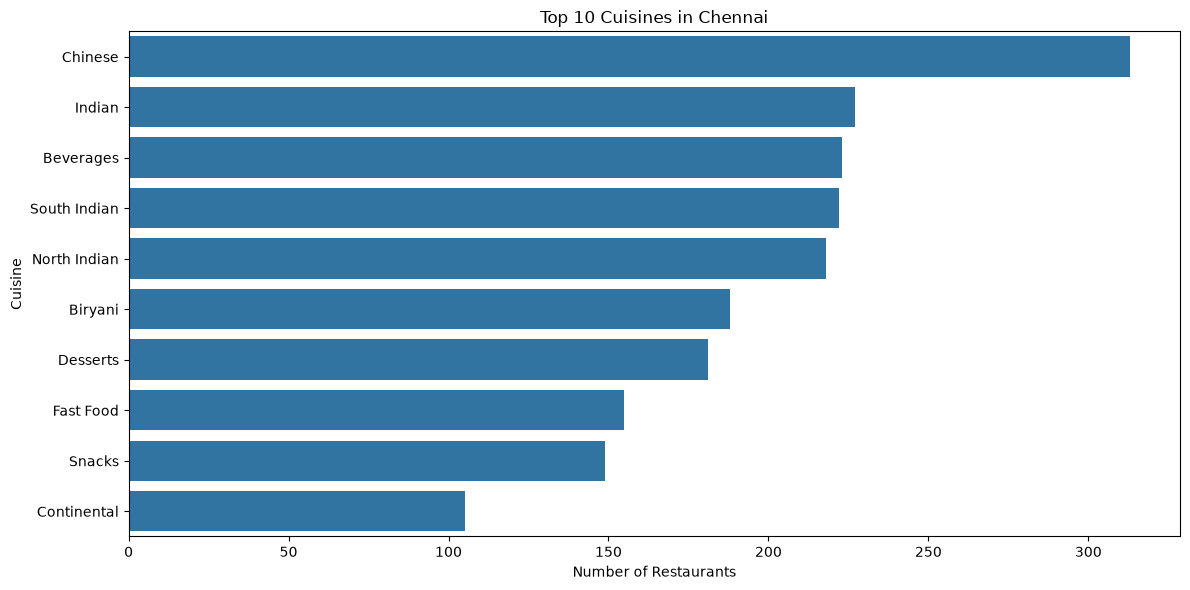

In [35]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=cuisine_counts.head(10).values,
    y=cuisine_counts.head(10).index
)

plt.title('Top 10 Cuisines in Chennai')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')

plt.tight_layout()
plt.show()

In [37]:
df_clean['Price Range'] = pd.cut(
    df_clean['Price'],
    bins=[0, 200, 400, 600, 1000, 3000],
    labels=['Budget', 'Affordable', 'Moderate', 'Premium', 'Luxury']
)

In [38]:
price_analysis = df_clean.groupby('Price Range', observed=True)['Avg ratings'].mean()

print(price_analysis)

Price Range
Budget        3.660882
Affordable    3.770513
Moderate      3.948246
Premium       3.995238
Luxury        4.011905
Name: Avg ratings, dtype: float64


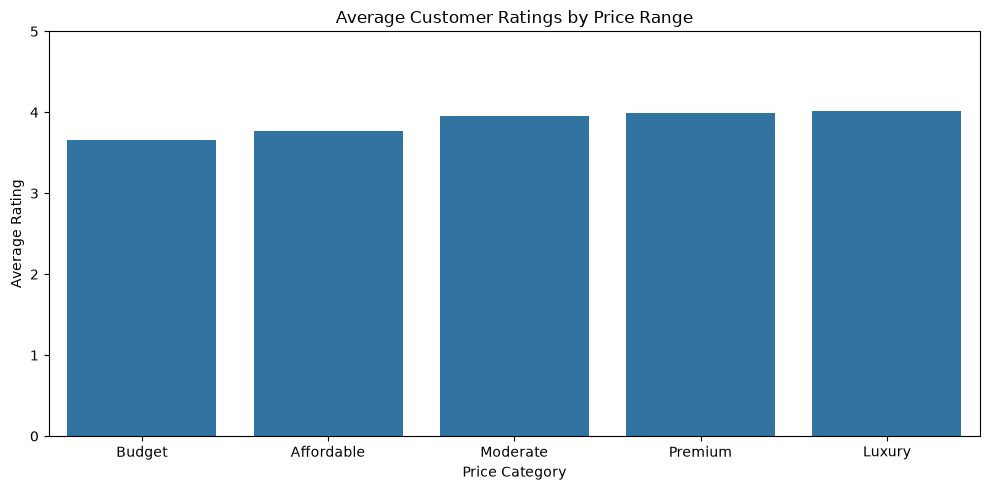

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=price_analysis.index,
    y=price_analysis.values
)

plt.title('Average Customer Ratings by Price Range')
plt.xlabel('Price Category')
plt.ylabel('Average Rating')

plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [40]:
area_counts = df_clean['Area'].value_counts()

print(area_counts.head(15))

Area
Perambur           89
Anna Nagar         73
Kilpauk            58
Egmore             57
Nungambakkam       51
Thousand Lights    48
Alwarpet           45
Mylapore           42
Annanagar          40
Purasaiwakkam      39
T. Nagar           38
Royapettah         35
Kodambakkam        34
George Town        34
Teynampet          31
Name: count, dtype: int64


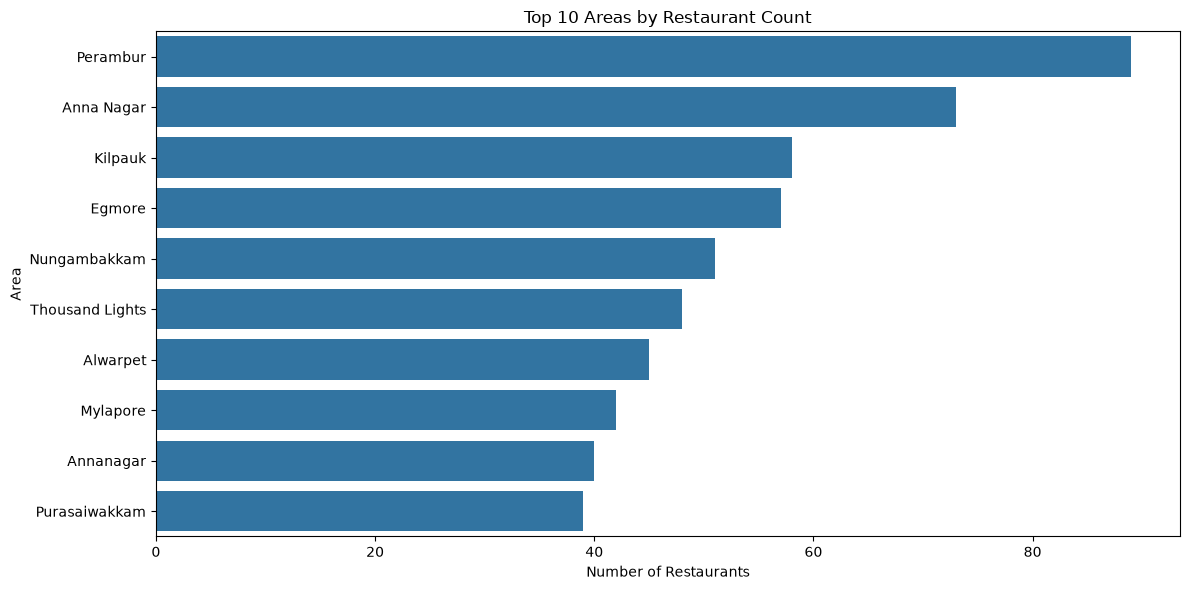

In [41]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=area_counts.head(10).values,
    y=area_counts.head(10).index
)

plt.title('Top 10 Areas by Restaurant Count')
plt.xlabel('Number of Restaurants')
plt.ylabel('Area')

plt.tight_layout()
plt.show()

In [42]:
print(area_counts.tail(10))

Area
Vishnu Garden                      1
Dr.Radhakrishnan Salai-Mylapore    1
Srinivas Towers                    1
Ra Puram                           1
Knk- Nungambakam (Cds)- Chennai    1
Saligramam                         1
Valasaravakkam                     1
Anna Nagar West                    1
Mogappair                          1
Mogapair                           1
Name: count, dtype: int64


In [ ]:
df_clean['Delivery Category'] = pd.cut(
    df_clean['Delivery time'],
    bins=[0, 30, 45, 60, 75, 100],
    labels=['Very Fast', 'Fast', 'Moderate', 'Slow', 'Very Slow']
)

In [44]:
delivery_analysis = df_clean.groupby(
    'Delivery Category',
    observed=True
)['Avg ratings'].mean()

print(delivery_analysis)

Delivery Category
Very Fast    4.266667
Fast         3.926875
Moderate     3.801639
Slow         3.748762
Very Slow    3.531193
Name: Avg ratings, dtype: float64


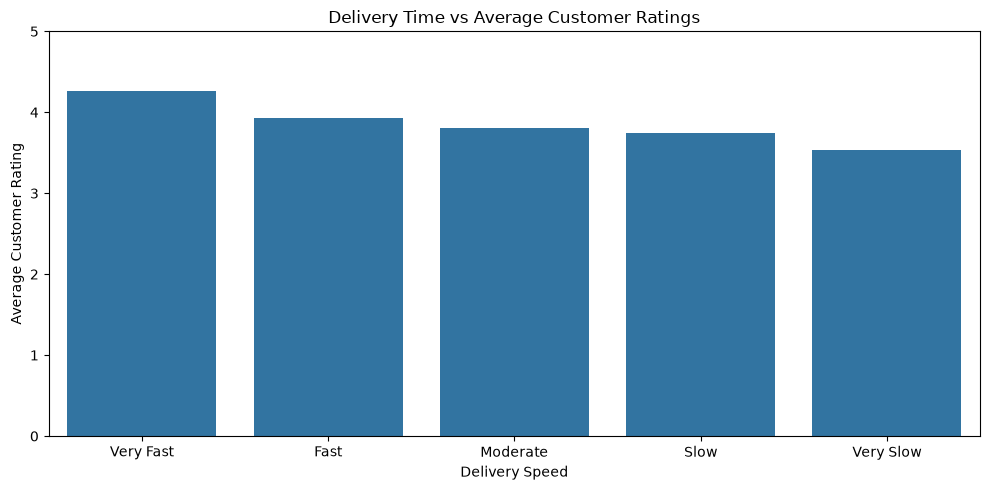

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=delivery_analysis.index,
    y=delivery_analysis.values
)

plt.title('Delivery Time vs Average Customer Ratings')
plt.xlabel('Delivery Speed')
plt.ylabel('Average Customer Rating')

plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [46]:
area_analysis = df_clean.groupby('Area').agg(
    Restaurant_Count=('Restaurant', 'nunique'),
    Average_Rating=('Avg ratings', 'mean'),
    Average_Rating_Count=('Total ratings', 'mean')
)

print(area_analysis.head(10))

                           Restaurant_Count  Average_Rating  \
Area                                                          
26                                        1        4.200000   
Alwarpet                                 45        4.000000   
Aminjikarai                              11        3.972727   
Anna Nagar                               73        4.146575   
Anna Nagar West                           1        4.400000   
Anna Nagar West Extension                 4        4.225000   
Anna Salai                                1        4.300000   
Annamalai Colony                          5        4.140000   
Annanagar                                40        3.257500   
Annanagar East                           19        3.852632   

                           Average_Rating_Count  
Area                                             
26                                   100.000000  
Alwarpet                             147.555556  
Aminjikarai                          277.27

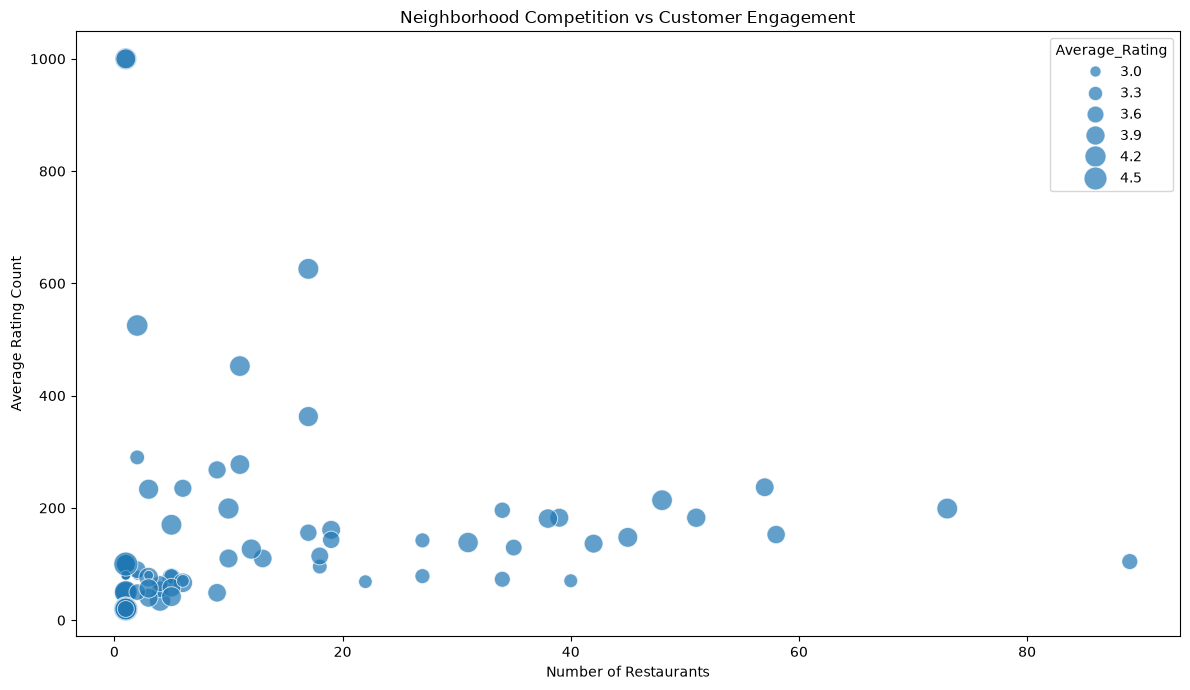

In [47]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=area_analysis,
    x='Restaurant_Count',
    y='Average_Rating_Count',
    size='Average_Rating',
    sizes=(50, 300),
    alpha=0.7
)

plt.title('Neighborhood Competition vs Customer Engagement')
plt.xlabel('Number of Restaurants')
plt.ylabel('Average Rating Count')

plt.tight_layout()
plt.show()

## Business Insights and Recommendations

In [48]:
print("TOP 5 CUISINES BY RESTAURANT COUNT")
print(cuisine_counts.head(5))

print("\nTOP 5 CUISINES BY AVERAGE RATING COUNT")
print(cuisine_demand.head(5))

print("\nAVERAGE RATINGS BY PRICE CATEGORY")
print(price_analysis)

print("\nAVERAGE RATINGS BY DELIVERY CATEGORY")
print(delivery_analysis)

print("\nTOP 5 AREAS BY RESTAURANT COUNT")
print(area_analysis.sort_values(
    by='Restaurant_Count',
    ascending=False
).head(5))

TOP 5 CUISINES BY RESTAURANT COUNT
Food type
Chinese         313
Indian          227
Beverages       223
South Indian    222
North Indian    218
Name: count, dtype: int64

TOP 5 CUISINES BY AVERAGE RATING COUNT
Food type
Punjab           5000.000000
Oriental          891.428571
Lucknowi          802.500000
European          781.428571
Mediterranean     701.250000
Name: Total ratings, dtype: float64

AVERAGE RATINGS BY PRICE CATEGORY
Price Range
Budget        3.660882
Affordable    3.770513
Moderate      3.948246
Premium       3.995238
Luxury        4.011905
Name: Avg ratings, dtype: float64

AVERAGE RATINGS BY DELIVERY CATEGORY
Delivery Category
Very Fast    4.266667
Fast         3.926875
Moderate     3.801639
Slow         3.748762
Very Slow    3.531193
Name: Avg ratings, dtype: float64

TOP 5 AREAS BY RESTAURANT COUNT
              Restaurant_Count  Average_Rating  Average_Rating_Count
Area                                                                
Perambur                    89 

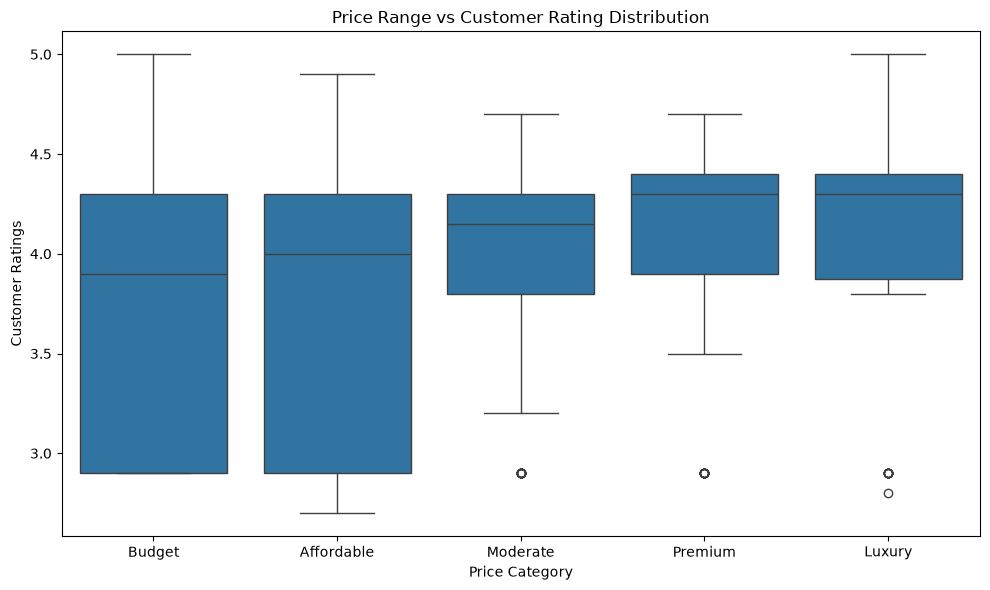

In [49]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='Price Range',
    y='Avg ratings'
)

plt.title('Price Range vs Customer Rating Distribution')
plt.xlabel('Price Category')
plt.ylabel('Customer Ratings')

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

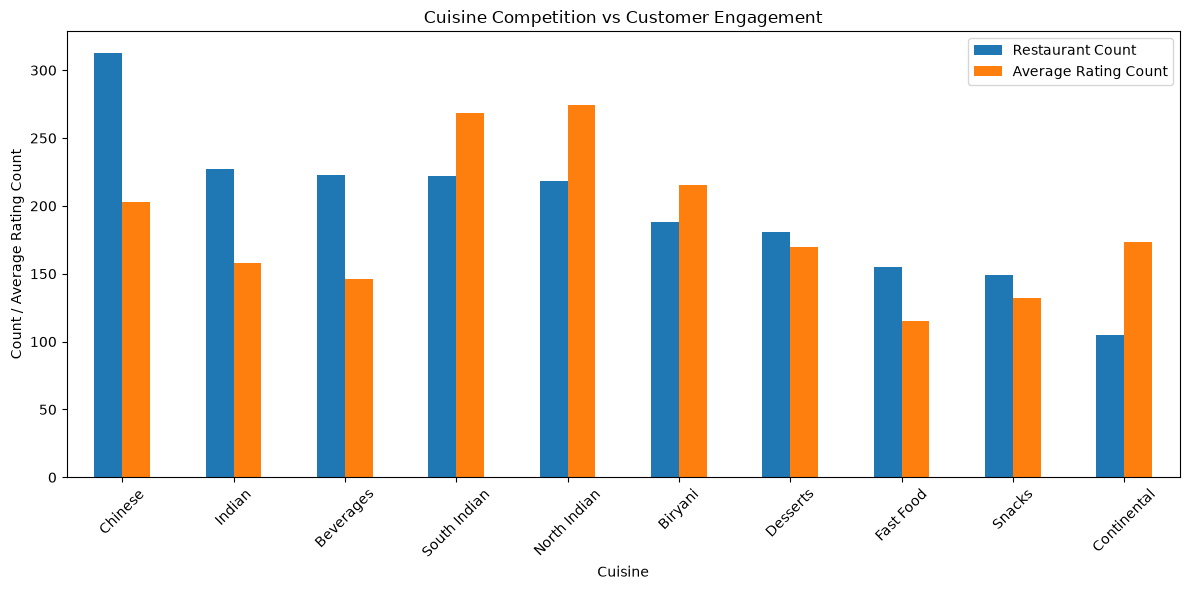

In [50]:
plt.figure(figsize=(12, 6))

cuisine_top = cuisine_analysis.sort_values(
    by='Restaurant Count',
    ascending=False
).head(10)

cuisine_top.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Cuisine Competition vs Customer Engagement')
plt.xlabel('Cuisine')
plt.ylabel('Count / Average Rating Count')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

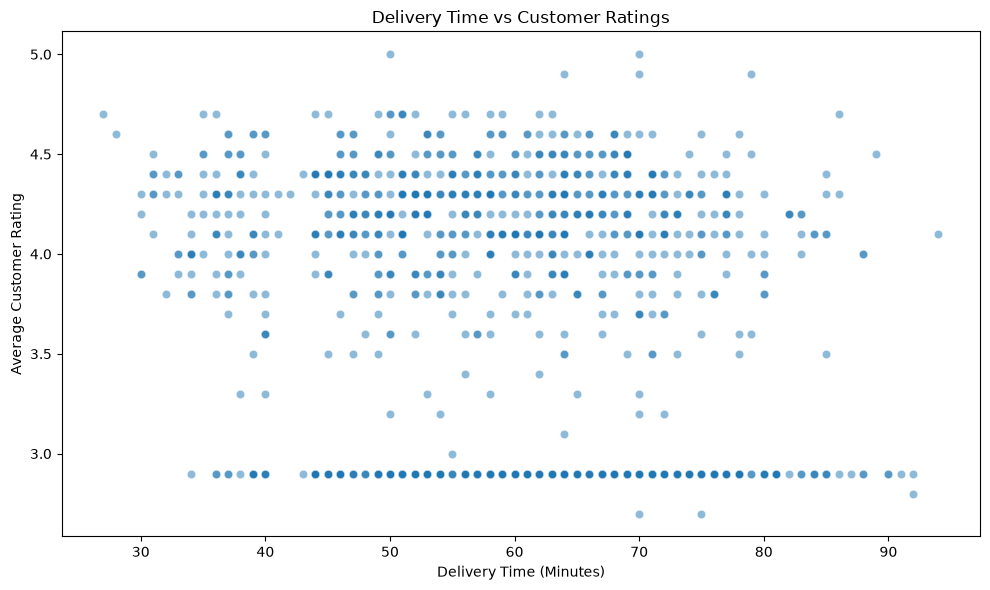

In [51]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='Delivery time',
    y='Avg ratings',
    alpha=0.5
)

plt.title('Delivery Time vs Customer Ratings')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Average Customer Rating')

plt.tight_layout()
plt.show()

In [52]:
correlation = df_clean['Delivery time'].corr(
    df_clean['Avg ratings']
)

print("Correlation:", correlation)

Correlation: -0.17955961071799073


# charts


In [54]:
import os

os.makedirs('charts', exist_ok=True)

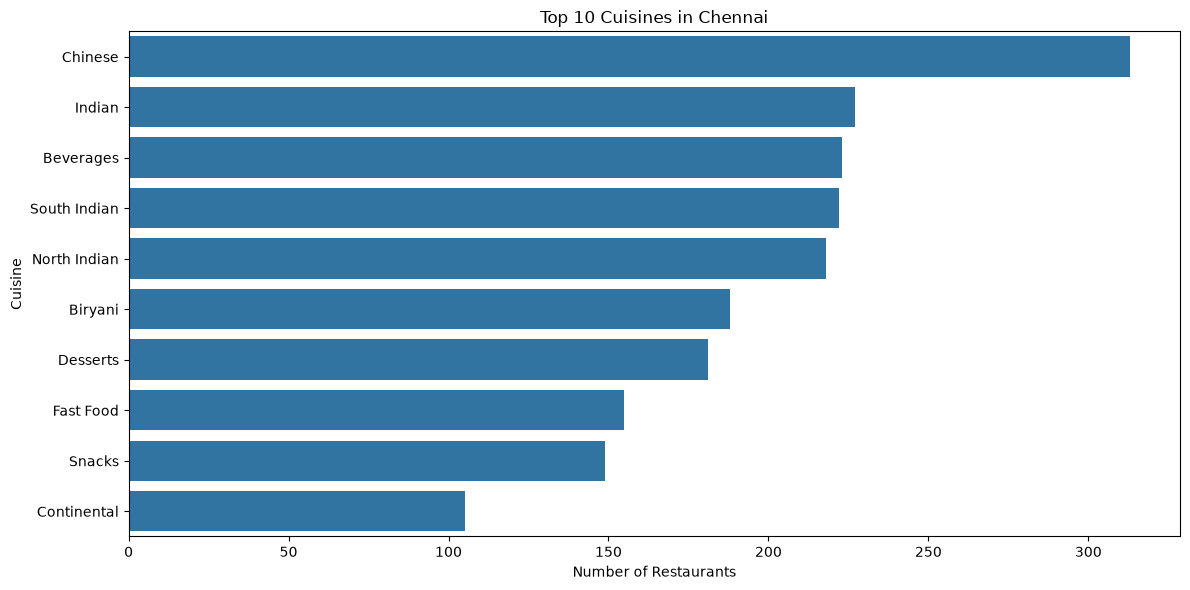

In [55]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=cuisine_counts.head(10).values,
    y=cuisine_counts.head(10).index
)

plt.title('Top 10 Cuisines in Chennai')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')

plt.tight_layout()

plt.savefig('charts/top_10_cuisines.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

In [56]:
import os

for file in os.listdir('charts'):
    print(file)

top_10_cuisines.png


In [57]:
!pip install python-pptx

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   --------------- ------------------------ 1.6/4.0 MB 8.0 MB/s eta 0:00:01
   ---------------------------------------  3.9/4.0 MB 9.9 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 8.9 MB/s  0:00:00

   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   ---------------------------------------- 0/3 [XlsxWriter]
   -------------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
import os

In [60]:
prs = Presentation()

prs.slide_width = Inches(13.33)
prs.slide_height = Inches(7.5)

print("PowerPoint presentation created!")

PowerPoint presentation created!


In [61]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(1), Inches(2), Inches(11), Inches(1)
)

title.text_frame.text = "Urban Food Delivery Market Analysis"

title.text_frame.paragraphs[0].font.size = Pt(32)
title.text_frame.paragraphs[0].font.bold = True

subtitle = slide.shapes.add_textbox(
    Inches(1), Inches(3.2), Inches(11), Inches(1)
)

subtitle.text_frame.text = "A Data-Driven Study of the Swiggy Chennai Restaurant Market"

subtitle.text_frame.paragraphs[0].font.size = Pt(18)

In [62]:
prs.save("Urban_Food_Delivery_Analysis.pptx")

print("PowerPoint saved successfully!")

PowerPoint saved successfully!


In [63]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)
title.text_frame.text = "Business Problem"

content = slide.shapes.add_textbox(
    Inches(1), Inches(2), Inches(11), Inches(4)
)

content.text_frame.text = (
    "A food entrepreneur wants to launch a new cloud kitchen in Chennai.\n\n"
    "The objective is to identify:\n"
    "1. High-potential cuisines.\n"
    "2. Suitable pricing strategies.\n"
    "3. Promising neighborhoods.\n"
    "4. The relationship between delivery time and customer ratings."
)

title.text_frame.paragraphs[0].font.size = Pt(30)
content.text_frame.paragraphs[0].font.size = Pt(20)

In [64]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)
title.text_frame.text = "Dataset & Data Cleaning"

content = slide.shapes.add_textbox(
    Inches(1), Inches(2), Inches(11), Inches(4)
)

content.text_frame.text = (
    "Dataset: Swiggy Chennai Restaurants\n\n"
    "Tools Used: Python, Pandas, Matplotlib and Seaborn\n\n"
    "Data Cleaning Activities:\n"
    "• Checked missing values and duplicates.\n"
    "• Converted numerical columns into appropriate data types.\n"
    "• Cleaned text columns.\n"
    "• Split and expanded cuisine categories.\n"
    "• Investigated unusual price values."
)

title.text_frame.paragraphs[0].font.size = Pt(30)
content.text_frame.paragraphs[0].font.size = Pt(18)

In [65]:
def add_chart_slide(title_text, image_path):

    slide = prs.slides.add_slide(prs.slide_layouts[6])

    title = slide.shapes.add_textbox(
        Inches(0.5), Inches(0.3), Inches(12), Inches(0.8)
    )

    title.text_frame.text = title_text
    title.text_frame.paragraphs[0].font.size = Pt(26)

    if os.path.exists(image_path):
        slide.shapes.add_picture(
            image_path,
            Inches(1),
            Inches(1.4),
            width=Inches(11)
        )
    else:
        print("Chart not found:", image_path)

In [66]:
add_chart_slide(
    "Cuisine Competition Analysis",
    "charts/top_10_cuisines.png"
)

add_chart_slide(
    "Price vs Customer Ratings",
    "charts/price_vs_ratings.png"
)

add_chart_slide(
    "Neighborhood Analysis",
    "charts/neighborhood_analysis.png"
)

add_chart_slide(
    "Delivery Time vs Customer Ratings",
    "charts/delivery_vs_ratings.png"
)

Chart not found: charts/price_vs_ratings.png
Chart not found: charts/neighborhood_analysis.png
Chart not found: charts/delivery_vs_ratings.png


In [67]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)
title.text_frame.text = "Conclusion & Recommendations"

content = slide.shapes.add_textbox(
    Inches(1), Inches(2), Inches(11), Inches(4)
)

content.text_frame.text = (
    "Recommendations for a Chennai Cloud Kitchen:\n\n"
    "• Select cuisines based on competition and customer engagement.\n"
    "• Choose pricing based on customer rating patterns.\n"
    "• Investigate localities with promising engagement and lower competition.\n"
    "• Consider delivery efficiency when designing operations.\n\n"
    "All recommendations should be validated using the actual analysis results."
)

title.text_frame.paragraphs[0].font.size = Pt(28)
content.text_frame.paragraphs[0].font.size = Pt(18)

In [68]:
prs.save("Urban_Food_Delivery_Analysis.pptx")

print("Presentation saved successfully!")
print("Total slides:", len(prs.slides))

Presentation saved successfully!
Total slides: 8


In [69]:
import os

print(os.listdir('charts'))

['top_10_cuisines.png']


In [70]:
import os

os.makedirs('charts', exist_ok=True)

print(os.listdir('charts'))

['top_10_cuisines.png']


In [71]:
plt.show()

In [72]:
plt.savefig('charts/top_10_cuisines.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

<Figure size 640x480 with 0 Axes>

In [73]:
import os

chart_files = os.listdir('charts')

for chart in chart_files:
    print(chart)

print("\nTotal charts saved:", len(chart_files))

top_10_cuisines.png

Total charts saved: 1


In [74]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [75]:
plt.tight_layout()

plt.savefig('charts/price_vs_ratings.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

<Figure size 640x480 with 0 Axes>

In [76]:
plt.savefig('charts/neighborhood_analysis.png',
            dpi=300,
            bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

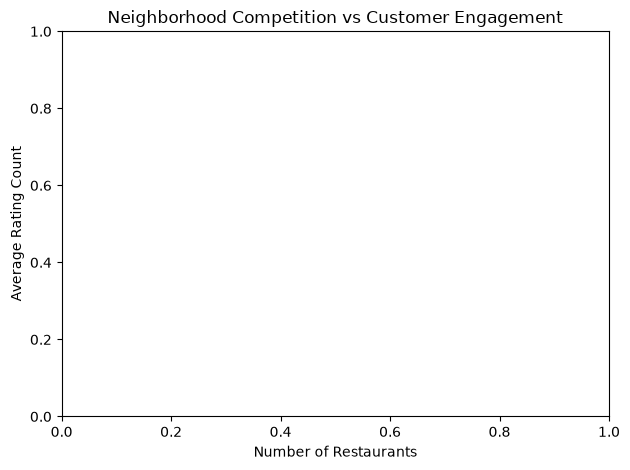

In [81]:
plt.title('Neighborhood Competition vs Customer Engagement')
plt.xlabel('Number of Restaurants')
plt.ylabel('Average Rating Count')

plt.tight_layout()

plt.savefig('charts/neighborhood_analysis.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

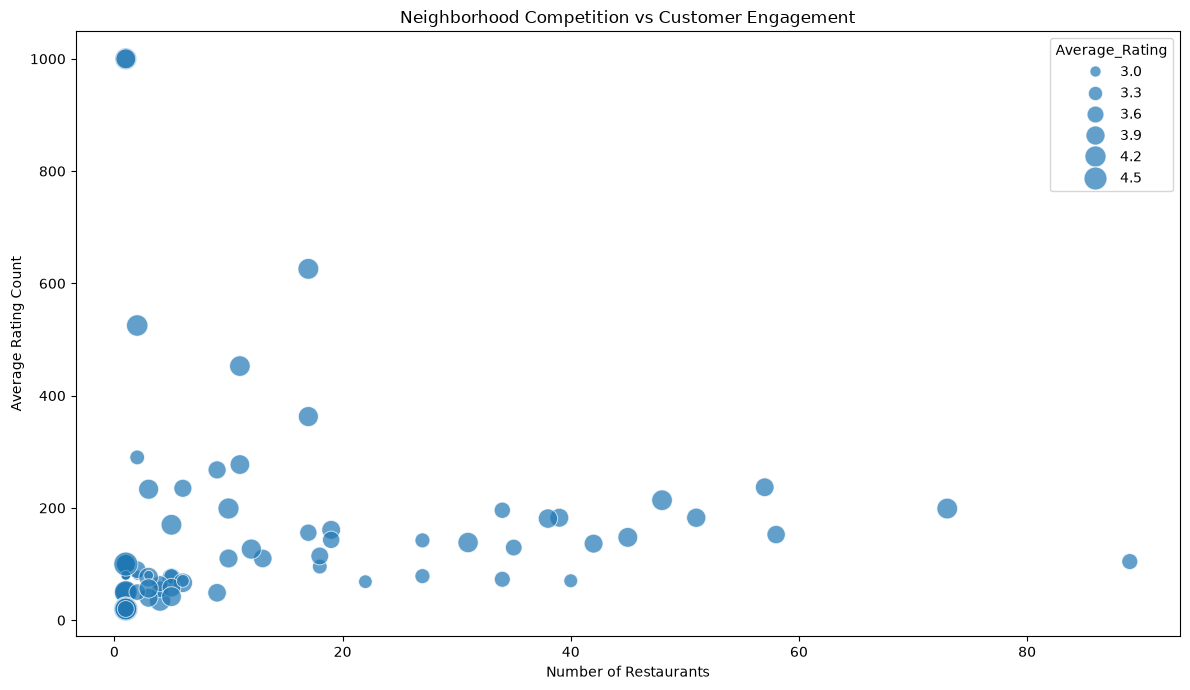

In [82]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=area_analysis,
    x='Restaurant_Count',
    y='Average_Rating_Count',
    size='Average_Rating',
    sizes=(50, 300),
    alpha=0.7
)

plt.title('Neighborhood Competition vs Customer Engagement')
plt.xlabel('Number of Restaurants')
plt.ylabel('Average Rating Count')

plt.tight_layout()

plt.savefig('charts/neighborhood_analysis.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

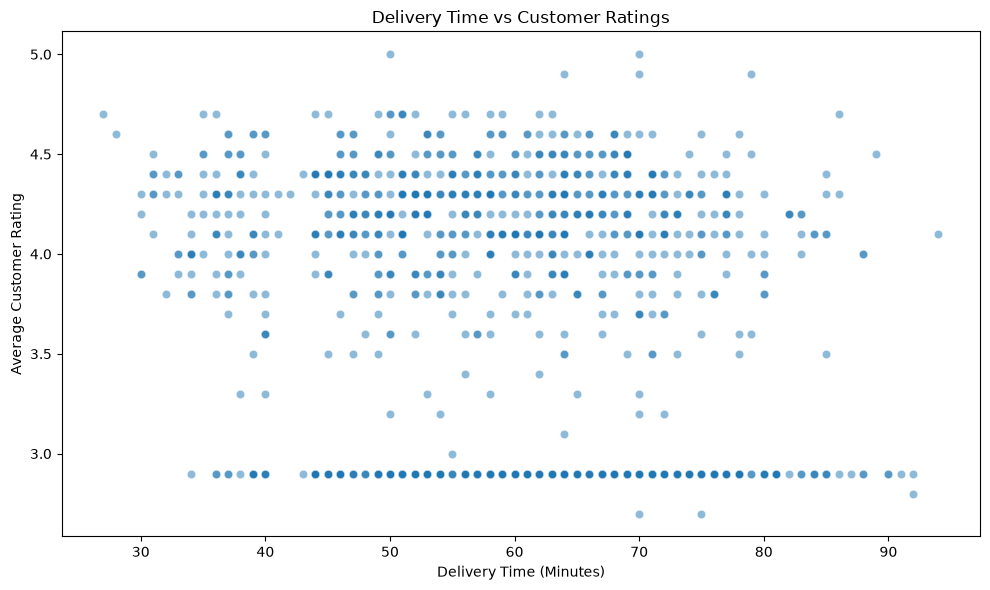

In [83]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='Delivery time',
    y='Avg ratings',
    alpha=0.5
)

plt.title('Delivery Time vs Customer Ratings')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Average Customer Rating')

plt.tight_layout()

plt.savefig('charts/delivery_vs_ratings.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

<Figure size 1200x600 with 0 Axes>

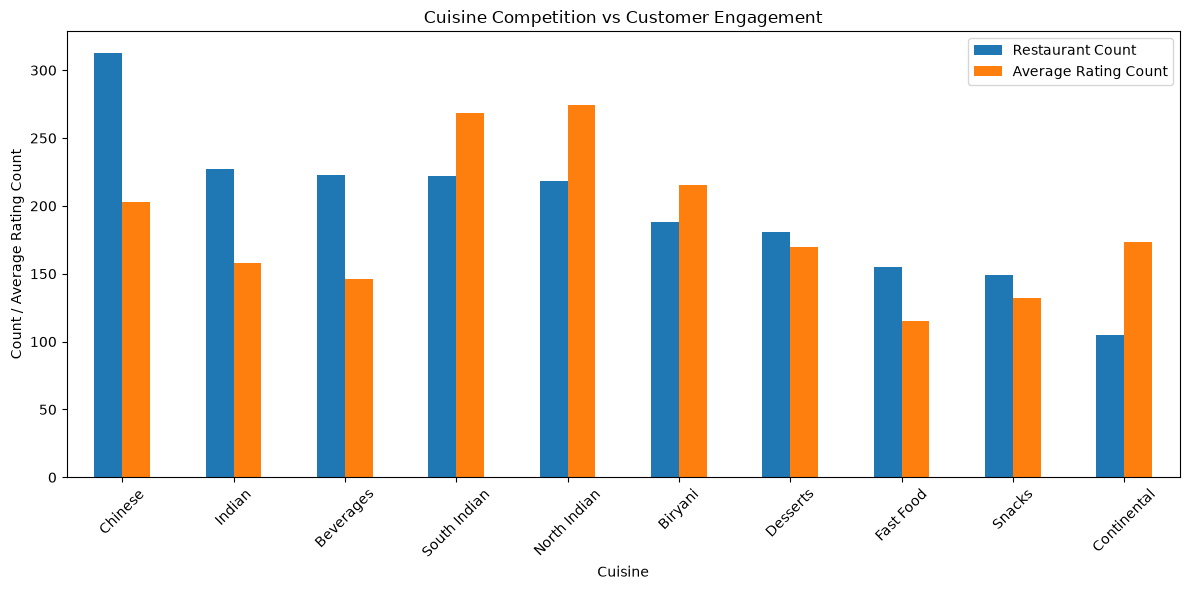

In [84]:
plt.figure(figsize=(12, 6))

cuisine_top = cuisine_analysis.sort_values(
    by='Restaurant Count',
    ascending=False
).head(10)

cuisine_top.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Cuisine Competition vs Customer Engagement')
plt.xlabel('Cuisine')
plt.ylabel('Count / Average Rating Count')

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('charts/cuisine_competition.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

In [85]:
import os

for file in os.listdir('charts'):
    print(file)

print("\nTotal charts saved:", len(os.listdir('charts')))

cuisine_competition.png
delivery_vs_ratings.png
neighborhood_analysis.png
price_vs_ratings.png
top_10_cuisines.png

Total charts saved: 5


In [86]:
from pptx import Presentation
from pptx.util import Inches, Pt
import os

# Open your existing presentation
prs = Presentation("Urban_Food_Delivery_Analysis.pptx")

def add_chart_slide(title_text, image_path):

    slide = prs.slides.add_slide(prs.slide_layouts[6])

    title = slide.shapes.add_textbox(
        Inches(0.5), Inches(0.3),
        Inches(12), Inches(0.8)
    )

    title.text_frame.text = title_text
    title.text_frame.paragraphs[0].font.size = Pt(26)

    slide.shapes.add_picture(
        image_path,
        Inches(1),
        Inches(1.4),
        width=Inches(11)
    )


# Add all five charts
add_chart_slide(
    "Top 10 Cuisines in Chennai",
    "charts/top_10_cuisines.png"
)

add_chart_slide(
    "Price vs Customer Ratings",
    "charts/price_vs_ratings.png"
)

add_chart_slide(
    "Neighborhood Analysis",
    "charts/neighborhood_analysis.png"
)

add_chart_slide(
    "Delivery Time vs Customer Ratings",
    "charts/delivery_vs_ratings.png"
)

add_chart_slide(
    "Cuisine Competition Analysis",
    "charts/cuisine_competition.png"
)

# Save presentation
prs.save("Urban_Food_Delivery_Analysis.pptx")

print("All five charts added successfully!")
print("Total slides:", len(prs.slides))

PackageNotFoundError: Package not found at 'Urban_Food_Delivery_Analysis.pptx'

In [87]:
import os

print("Current folder:", os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current folder: c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai

Files available:
['charts', 'Swiggy_Analysis.ipynb', 'Swiggy_Chennai.csv', 'Urban_Food_Delivery_Analysis.pptx']


In [88]:
import os

for root, dirs, files in os.walk('.'):
    for file in files:
        if file.endswith('.pptx'):
            print(os.path.join(root, file))

.\Urban_Food_Delivery_Analysis.pptx


In [90]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nPowerPoint files in this folder:")

for root, dirs, files in os.walk(os.getcwd()):
    for file in files:
        if file.endswith(".pptx"):
            print(os.path.join(root, file))

Current working directory:
c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai

PowerPoint files in this folder:
c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Urban_Food_Delivery_Analysis.pptx


In [91]:
from pptx import Presentation

prs = Presentation(ppt_path)

print("Total slides:", len(prs.slides))

for i, slide in enumerate(prs.slides, start=1):
    print(f"Slide {i}: {len(slide.shapes)} objects")

PackageNotFoundError: Package not found at 'C:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Urban_Food_Delivery_Analysis.pptx'

In [92]:
ppt_path = r"PASTE_YOUR_COPIED_PATH_HERE"

import os

print("File exists:", os.path.exists(ppt_path))

File exists: False


In [93]:
import os

search_folder = r"C:\Users\kames\OneDrive\Desktop"

for root, dirs, files in os.walk(search_folder):
    for file in files:
        if file == "Urban_Food_Delivery_Analysis.pptx":
            print("FOUND:", os.path.join(root, file))

FOUND: C:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Urban_Food_Delivery_Analysis.pptx


In [94]:
from pptx import Presentation
import os

ppt_path = r"C:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Urban_Food_Delivery_Analysis.pptx"

print("File exists:", os.path.exists(ppt_path))

prs = Presentation(ppt_path)

print("PPT opened successfully!")
print("Current slide count:", len(prs.slides))

File exists: True


PackageNotFoundError: Package not found at 'C:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Urban_Food_Delivery_Analysis.pptx'

In [95]:
import os
import zipfile

ppt_path = r"C:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Urban_Food_Delivery_Analysis.pptx"

print("File exists:", os.path.exists(ppt_path))
print("File size:", os.path.getsize(ppt_path), "bytes")

print("Valid PowerPoint ZIP:", zipfile.is_zipfile(ppt_path))

File exists: True
File size: 133361 bytes
Valid PowerPoint ZIP: False


In [96]:
import zipfile
import os

for file in os.listdir("charts"):
    print(file)

cuisine_competition.png
delivery_vs_ratings.png
neighborhood_analysis.png
price_vs_ratings.png
top_10_cuisines.png


In [97]:
!pip install python-pptx


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [98]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

prs_new = Presentation()
prs_new.slide_width = Inches(13.33)
prs_new.slide_height = Inches(7.5)

print("New PowerPoint created!")

New PowerPoint created!


In [99]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(1), Inches(2.3), Inches(11), Inches(1)
)

title.text_frame.text = "Urban Food Delivery Market Analysis"
title.text_frame.paragraphs[0].font.size = Pt(32)
title.text_frame.paragraphs[0].font.bold = True

subtitle = slide.shapes.add_textbox(
    Inches(1), Inches(3.5), Inches(11), Inches(1)
)

subtitle.text_frame.text = (
    "A Data-Driven Study of the Swiggy Chennai Restaurant Market"
)

subtitle.text_frame.paragraphs[0].font.size = Pt(19)

prs_new.save("Urban_Food_Delivery_Analysis_Final.pptx")

print("Cover slide created!")

Cover slide created!


In [100]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)
title.text_frame.text = "Business Problem"
title.text_frame.paragraphs[0].font.size = Pt(30)
title.text_frame.paragraphs[0].font.bold = True

content = slide.shapes.add_textbox(
    Inches(1), Inches(2), Inches(11), Inches(4)
)

content.text_frame.text = (
    "A food entrepreneur wants to launch a new cloud kitchen in Chennai.\n\n"
    "The objective is to identify:\n\n"
    "1. High-potential cuisines.\n"
    "2. Suitable pricing strategies.\n"
    "3. Promising neighborhoods.\n"
    "4. The relationship between delivery time and customer ratings."
)

content.text_frame.paragraphs[0].font.size = Pt(21)

prs_new.save("Urban_Food_Delivery_Analysis_Final.pptx")

print("Business Problem slide added!")
print("Total slides:", len(prs_new.slides))

PermissionError: [Errno 13] Permission denied: 'Urban_Food_Delivery_Analysis_Final.pptx'

In [101]:
import os

ppt_name = "Urban_Food_Delivery_Analysis_Final_v2.pptx"

prs_new.save(ppt_name)

print("Presentation saved successfully!")
print("Total slides:", len(prs_new.slides))
print("File exists:", os.path.exists(ppt_name))

Presentation saved successfully!
Total slides: 2
File exists: True


In [103]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)

title.text_frame.text = "Dataset & Data Cleaning"
title.text_frame.paragraphs[0].font.size = Pt(30)
title.text_frame.paragraphs[0].font.bold = True

content = slide.shapes.add_textbox(
    Inches(1), Inches(1.8), Inches(11), Inches(5)
)

content.text_frame.text = (
    "Dataset: Swiggy Chennai Restaurants\n\n"
    "Tools Used:\n"
    "Python, Pandas, Matplotlib and Seaborn\n\n"
    "Data Cleaning Activities:\n"
    "• Checked missing values and duplicate records.\n"
    "• Converted numerical columns into appropriate data types.\n"
    "• Cleaned text columns.\n"
    "• Split and expanded cuisine categories.\n"
    "• Investigated unusual price values.\n\n"
    "Dataset Size: 1,096 unique restaurants"
)

content.text_frame.paragraphs[0].font.size = Pt(19)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Dataset slide added!")
print("Total slides:", len(prs_new.slides))

Dataset slide added!
Total slides: 4


In [104]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.5), Inches(0.3), Inches(12), Inches(0.7)
)

title.text_frame.text = "Top 10 Cuisines in Chennai"
title.text_frame.paragraphs[0].font.size = Pt(26)
title.text_frame.paragraphs[0].font.bold = True

slide.shapes.add_picture(
    "charts/top_10_cuisines.png",
    Inches(1), Inches(1.3),
    width=Inches(11)
)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Top 10 Cuisines chart added!")
print("Total slides:", len(prs_new.slides))

Top 10 Cuisines chart added!
Total slides: 5


In [105]:
for i, slide in enumerate(prs_new.slides, start=1):
    titles = [
        shape.text for shape in slide.shapes
        if shape.has_text_frame and shape.text.strip()
    ]
    print(f"Slide {i}: {titles}")

Slide 1: ['Urban Food Delivery Market Analysis', 'A Data-Driven Study of the Swiggy Chennai Restaurant Market']
Slide 2: ['Business Problem', 'A food entrepreneur wants to launch a new cloud kitchen in Chennai.\n\nThe objective is to identify:\n\n1. High-potential cuisines.\n2. Suitable pricing strategies.\n3. Promising neighborhoods.\n4. The relationship between delivery time and customer ratings.']
Slide 3: ['Dataset & Data Cleaning', 'Dataset: Swiggy Chennai Restaurants\n\nTools Used:\nPython, Pandas, Matplotlib and Seaborn\n\nData Cleaning Activities:\n• Checked missing values and duplicate records.\n• Converted numerical columns into appropriate data types.\n• Cleaned text columns.\n• Split and expanded cuisine categories.\n• Investigated unusual price values.\n\nDataset Size: 1,096 unique restaurants']
Slide 4: ['Dataset & Data Cleaning', 'Dataset: Swiggy Chennai Restaurants\n\nTools Used:\nPython, Pandas, Matplotlib and Seaborn\n\nData Cleaning Activities:\n• Checked missing val

In [106]:
# Remove slide 4 (index 3)
slide_id_list = prs_new.slides._sldIdLst
slide_to_remove = slide_id_list[3]

prs_new.part.drop_rel(slide_to_remove.rId)
slide_id_list.remove(slide_to_remove)

# Save updated presentation
prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Duplicate slide removed!")
print("Total slides:", len(prs_new.slides))

Duplicate slide removed!
Total slides: 4


In [107]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.5), Inches(0.3), Inches(12), Inches(0.7)
)

title.text_frame.text = "Price vs Customer Ratings"
title.text_frame.paragraphs[0].font.size = Pt(26)
title.text_frame.paragraphs[0].font.bold = True

slide.shapes.add_picture(
    "charts/price_vs_ratings.png",
    Inches(1), Inches(1.3),
    width=Inches(11)
)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Price vs Ratings chart added!")
print("Total slides:", len(prs_new.slides))

Price vs Ratings chart added!
Total slides: 5


C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\zipfile\__init__.py:1661: UserWarning: Duplicate name: 'ppt/slides/slide5.xml'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\zipfile\__init__.py:1661: UserWarning: Duplicate name: 'ppt/slides/_rels/slide5.xml.rels'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


In [108]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.5), Inches(0.3), Inches(12), Inches(0.7)
)

title.text_frame.text = "Neighborhood Competition vs Customer Engagement"
title.text_frame.paragraphs[0].font.size = Pt(24)
title.text_frame.paragraphs[0].font.bold = True

slide.shapes.add_picture(
    "charts/neighborhood_analysis.png",
    Inches(1), Inches(1.3),
    width=Inches(11)
)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Neighborhood Analysis chart added!")
print("Total slides:", len(prs_new.slides))

Neighborhood Analysis chart added!
Total slides: 6


In [109]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.5), Inches(0.3), Inches(12), Inches(0.7)
)

title.text_frame.text = "Delivery Time vs Customer Ratings"
title.text_frame.paragraphs[0].font.size = Pt(26)
title.text_frame.paragraphs[0].font.bold = True

slide.shapes.add_picture(
    "charts/delivery_vs_ratings.png",
    Inches(1), Inches(1.3),
    width=Inches(11)
)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Delivery chart added!")
print("Total slides:", len(prs_new.slides))

Delivery chart added!
Total slides: 7


In [110]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.5), Inches(0.3), Inches(12), Inches(0.7)
)

title.text_frame.text = "Delivery Time vs Customer Ratings"
title.text_frame.paragraphs[0].font.size = Pt(26)
title.text_frame.paragraphs[0].font.bold = True

slide.shapes.add_picture(
    "charts/delivery_vs_ratings.png",
    Inches(1), Inches(1.3),
    width=Inches(11)
)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Delivery chart added!")
print("Total slides:", len(prs_new.slides))

Delivery chart added!
Total slides: 8


In [111]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)

title.text_frame.text = "Key Business Insights"
title.text_frame.paragraphs[0].font.size = Pt(30)
title.text_frame.paragraphs[0].font.bold = True

content = slide.shapes.add_textbox(
    Inches(1), Inches(1.8), Inches(11), Inches(5)
)

content.text_frame.text = (
    "1. Indian cuisine has the highest representation in the dataset "
    "with 56 cuisine listings.\n\n"
    "2. South Indian cuisine follows with 49 listings.\n\n"
    "3. Fast Food, Chinese and North Indian also have notable representation.\n\n"
    "4. Cuisine competition should be evaluated alongside customer engagement.\n\n"
    "5. Total ratings can be used as a customer engagement proxy, "
    "not as actual order volume."
)

content.text_frame.paragraphs[0].font.size = Pt(19)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Business Insights slide added!")
print("Total slides:", len(prs_new.slides))

Business Insights slide added!
Total slides: 9


In [112]:
slide = prs_new.slides.add_slide(prs_new.slide_layouts[6])

title = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(1)
)

title.text_frame.text = "Recommendations & Conclusion"
title.text_frame.paragraphs[0].font.size = Pt(28)
title.text_frame.paragraphs[0].font.bold = True

content = slide.shapes.add_textbox(
    Inches(1), Inches(1.8), Inches(11), Inches(5)
)

content.text_frame.text = (
    "Recommendations for a Chennai Cloud Kitchen:\n\n"
    "1. Evaluate cuisines with a balance of competition and customer engagement.\n\n"
    "2. Select a suitable price range based on customer rating patterns.\n\n"
    "3. Explore neighborhoods with promising engagement and manageable competition.\n\n"
    "4. Focus on efficient delivery operations to improve customer experience.\n\n"
    "Conclusion:\n"
    "Use data-driven insights to support the cloud kitchen launch decision."
)

content.text_frame.paragraphs[0].font.size = Pt(18)

prs_new.save("Urban_Food_Delivery_Analysis_Final_v2.pptx")

print("Final slide added successfully!")
print("Total slides:", len(prs_new.slides))

Final slide added successfully!
Total slides: 10


In [113]:
import os
import zipfile

ppt_path = "Urban_Food_Delivery_Analysis_Final_v2.pptx"

print("File exists:", os.path.exists(ppt_path))
print("File size:", os.path.getsize(ppt_path), "bytes")
print("Valid PPTX:", zipfile.is_zipfile(ppt_path))

with zipfile.ZipFile(ppt_path, 'r') as ppt:
    print("ZIP integrity:", ppt.testzip())

File exists: True
File size: 345487 bytes
Valid PPTX: False


PermissionError: [Errno 13] Permission denied: 'Urban_Food_Delivery_Analysis_Final_v2.pptx'

In [114]:
import os
import zipfile
import shutil

source = "Urban_Food_Delivery_Analysis_Final_v2.pptx"
backup = "Urban_Food_Delivery_Analysis_Diagnostic.pptx"

shutil.copy2(source, backup)

print("Backup created:", os.path.exists(backup))
print("File size:", os.path.getsize(backup))

print("Valid PPTX:", zipfile.is_zipfile(backup))

with zipfile.ZipFile(backup, 'r') as ppt:
    print("ZIP integrity:", ppt.testzip())


Backup created: True
File size: 345487
Valid PPTX: True
ZIP integrity: None


In [115]:
from pptx import Presentation
import zipfile
import xml.etree.ElementTree as ET

ppt_path = "Urban_Food_Delivery_Analysis_Diagnostic.pptx"

# Check all XML files
with zipfile.ZipFile(ppt_path, 'r') as ppt:
    for name in ppt.namelist():
        if name.endswith('.xml') or name.endswith('.rels'):
            try:
                ET.fromstring(ppt.read(name))
            except Exception as e:
                print("Problem in:", name)
                print(e)

print("XML inspection completed!")

# Try opening with python-pptx
try:
    test_prs = Presentation(ppt_path)
    print("PowerPoint package opened successfully!")
    print("Total slides:", len(test_prs.slides))
except Exception as e:
    print("PowerPoint loading error:", repr(e))

XML inspection completed!
PowerPoint package opened successfully!
Total slides: 10


In [116]:
from pptx import Presentation

source = Presentation(
    "Urban_Food_Delivery_Analysis_Diagnostic.pptx"
)

clean_path = "Urban_Food_Delivery_Analysis_Clean.pptx"

source.save(clean_path)

print("Clean presentation saved!")
print("Total slides:", len(source.slides))

Clean presentation saved!
Total slides: 10


In [117]:
import zipfile
from pptx import Presentation

clean_path = "Urban_Food_Delivery_Analysis_Clean.pptx"

print("Valid ZIP:", zipfile.is_zipfile(clean_path))

test = Presentation(clean_path)

print("Slides:", len(test.slides))

Valid ZIP: True
Slides: 10


In [1]:
import os
from pathlib import Path

# Check current project location
print("Current folder:", os.getcwd())

# Create a fresh output folder
output_folder = Path("Final_Presentation")

output_folder.mkdir(exist_ok=True)

# Create charts folder
charts_folder = output_folder / "charts"

charts_folder.mkdir(exist_ok=True)

print("New presentation folders created successfully!")

Current folder: c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai
New presentation folders created successfully!


In [2]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [
        "Final_Presentation",
        ".ipynb_checkpoints"
    ]]

    for file in files:
        if file.endswith((".png", ".jpg", ".jpeg")):
            print(os.path.join(root, file))

.\charts\cuisine_competition.png
.\charts\delivery_vs_ratings.png
.\charts\neighborhood_analysis.png
.\charts\price_vs_ratings.png
.\charts\top_10_cuisines.png


In [3]:
from PIL import Image
from pathlib import Path

chart_folder = Path("charts")

for file in chart_folder.glob("*.png"):
    try:
        img = Image.open(file)
        img.verify()

        img = Image.open(file)

        print(
            file.name,
            "| Size:", img.size,
            "| Status: Valid"
        )

    except Exception as e:
        print(file.name, "| Error:", e)

cuisine_competition.png | Size: (3569, 1767) | Status: Valid
delivery_vs_ratings.png | Size: (2970, 1768) | Status: Valid
neighborhood_analysis.png | Size: (3569, 2068) | Status: Valid
price_vs_ratings.png | Size: (1980, 1500) | Status: Valid
top_10_cuisines.png | Size: (1980, 1500) | Status: Valid


In [4]:
import shutil
from pathlib import Path

source = Path("charts")
destination = Path("Final_Presentation/charts")

for file in source.glob("*.png"):
    shutil.copy2(file, destination / file.name)

print("Charts copied successfully!")

for file in destination.glob("*.png"):
    print(file.name, "->", file.stat().st_size, "bytes")

Charts copied successfully!
cuisine_competition.png -> 141664 bytes
delivery_vs_ratings.png -> 148954 bytes
neighborhood_analysis.png -> 227696 bytes
price_vs_ratings.png -> 15139 bytes
top_10_cuisines.png -> 15139 bytes


In [5]:
try:
    import pptx
    print("python-pptx is installed!")
    print("Version:", pptx.__version__)

except ImportError:
    print("Installing python-pptx...")
    %pip install python-pptx

python-pptx is installed!
Version: 1.0.2


In [6]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN

# Create new presentation
prs = Presentation()

# Set widescreen 16:9
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

# Theme colors
NAVY = RGBColor(20, 40, 75)
BLUE = RGBColor(45, 110, 190)
WHITE = RGBColor(255, 255, 255)
GREY = RGBColor(90, 100, 115)

# Save location
output_path = "Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx"

print("Presentation foundation created!")
print("Slide size: 16:9 Widescreen")
print("Theme: White, Navy and Blue")

Presentation foundation created!
Slide size: 16:9 Widescreen
Theme: White, Navy and Blue


In [7]:
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN
from pptx.enum.shapes import MSO_SHAPE

# Create slide
slide = prs.slides.add_slide(prs.slide_layouts[6])

# White background
background = slide.background
background.fill.solid()
background.fill.fore_color.rgb = WHITE

# Top blue accent bar
shape = slide.shapes.add_shape(
    MSO_SHAPE.RECTANGLE,
    Inches(0), Inches(0),
    Inches(13.333), Inches(0.18)
)
shape.fill.solid()
shape.fill.fore_color.rgb = BLUE
shape.line.fill.background()

# Main title
box = slide.shapes.add_textbox(
    Inches(0.9), Inches(1.8),
    Inches(11.5), Inches(1.2)
)

tf = box.text_frame
p = tf.paragraphs[0]
p.text = "URBAN FOOD DELIVERY"
p.font.size = Pt(34)
p.font.bold = True
p.font.color.rgb = NAVY

# Subtitle
box = slide.shapes.add_textbox(
    Inches(0.95), Inches(3.0),
    Inches(11), Inches(0.7)
)

p = box.text_frame.paragraphs[0]
p.text = "ANALYSIS – CHENNAI"
p.font.size = Pt(27)
p.font.color.rgb = BLUE

# Description
box = slide.shapes.add_textbox(
    Inches(0.95), Inches(4.0),
    Inches(10.5), Inches(0.8)
)

p = box.text_frame.paragraphs[0]
p.text = "Exploring restaurant trends, pricing, ratings and delivery patterns"
p.font.size = Pt(17)
p.font.color.rgb = GREY

# Tools
box = slide.shapes.add_textbox(
    Inches(0.95), Inches(5.3),
    Inches(10.5), Inches(0.5)
)

p = box.text_frame.paragraphs[0]
p.text = "PYTHON  |  PANDAS  |  MATPLOTLIB  |  SEABORN"
p.font.size = Pt(13)
p.font.bold = True
p.font.color.rgb = NAVY

# Save
prs.save(output_path)

print("Slide 1 created successfully!")

Slide 1 created successfully!


In [8]:
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(0.8)
)
p = box.text_frame.paragraphs[0]
p.text = "PROJECT OVERVIEW"
p.font.size = Pt(30)
p.font.bold = True
p.font.color.rgb = NAVY

# Introduction
box = slide.shapes.add_textbox(
    Inches(0.8), Inches(1.6), Inches(11.5), Inches(1)
)
p = box.text_frame.paragraphs[0]
p.text = (
    "This project explores the urban food delivery ecosystem "
    "in Chennai using restaurant-level data and Python."
)
p.font.size = Pt(19)
p.font.color.rgb = GREY

# Key objectives
objectives = [
    "Analyze popular cuisines and restaurant competition",
    "Understand restaurant pricing patterns",
    "Explore customer ratings and delivery trends",
    "Identify neighborhood-level restaurant distribution",
    "Generate actionable business insights"
]

box = slide.shapes.add_textbox(
    Inches(1.0), Inches(3.0), Inches(11), Inches(3.5)
)

tf = box.text_frame
tf.clear()

for i, item in enumerate(objectives):
    p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
    p.text = "• " + item
    p.font.size = Pt(20)
    p.font.color.rgb = NAVY
    p.space_after = Pt(22)

prs.save(output_path)

print("Slide 2 created successfully!")

Slide 2 created successfully!


In [9]:
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(0.8)
)
p = box.text_frame.paragraphs[0]
p.text = "DATASET OVERVIEW"
p.font.size = Pt(30)
p.font.bold = True
p.font.color.rgb = NAVY

# Dataset statistics
total_rows = df.shape[0]
total_columns = df.shape[1]

stats = [
    ("TOTAL RECORDS", f"{total_rows:,}"),
    ("TOTAL COLUMNS", str(total_columns)),
    ("DATA SOURCE", "Swiggy Chennai Dataset")
]

positions = [0.9, 4.8, 8.7]

for (label, value), x in zip(stats, positions):
    box = slide.shapes.add_textbox(
        Inches(x), Inches(2.0), Inches(3.2), Inches(1.5)
    )
    tf = box.text_frame

    p = tf.paragraphs[0]
    p.text = label
    p.font.size = Pt(15)
    p.font.bold = True
    p.font.color.rgb = GREY
    p.alignment = PP_ALIGN.CENTER

    p = tf.add_paragraph()
    p.text = value
    p.font.size = Pt(25)
    p.font.bold = True
    p.font.color.rgb = BLUE
    p.alignment = PP_ALIGN.CENTER

# Important dataset fields
box = slide.shapes.add_textbox(
    Inches(1.0), Inches(4.1), Inches(11), Inches(2.2)
)
tf = box.text_frame
tf.clear()

p = tf.paragraphs[0]
p.text = "KEY DATA FIELDS"
p.font.size = Pt(21)
p.font.bold = True
p.font.color.rgb = NAVY

p = tf.add_paragraph()
p.text = " | ".join(str(col) for col in df.columns[:12])
p.font.size = Pt(17)
p.font.color.rgb = GREY
p.space_before = Pt(15)

prs.save(output_path)

print("Slide 3 created successfully!")
print("Dataset shape:", df.shape)

NameError: name 'df' is not defined

In [10]:
print(df.head())

NameError: name 'df' is not defined

In [16]:
import pandas as pd

df = pd.read_csv(
    "Swiggy_Chennai.csv",
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded!")
print("Shape:", df.shape)
print(df.head())

C:\Users\kames\AppData\Local\Temp\ipykernel_19924\2165551426.py:3: ParserWarning: Skipping line 11: Expected 4 fields in line 11, saw 6

  df = pd.read_csv(
C:\Users\kames\AppData\Local\Temp\ipykernel_19924\2165551426.py:3: ParserWarning: Skipping line 17: Expected 4 fields in line 17, saw 5

  df = pd.read_csv(
C:\Users\kames\AppData\Local\Temp\ipykernel_19924\2165551426.py:3: ParserWarning: Skipping line 24: Expected 4 fields in line 24, saw 5

  df = pd.read_csv(
C:\Users\kames\AppData\Local\Temp\ipykernel_19924\2165551426.py:3: ParserWarning: Skipping line 26: Expected 4 fields in line 26, saw 6

  df = pd.read_csv(
C:\Users\kames\AppData\Local\Temp\ipykernel_19924\2165551426.py:3: ParserWarning: Skipping line 35: Expected 4 fields in line 35, saw 7

  df = pd.read_csv(
C:\Users\kames\AppData\Local\Temp\ipykernel_19924\2165551426.py:3: ParserWarning: Skipping line 46: Expected 4 fields in line 46, saw 7

  df = pd.read_csv(
C:\Users\kames\AppData\Local\Temp\ipykernel_19924\21655514

Dataset loaded!
Shape: (958, 1)
                                                                                  ID\tArea\tCity\tRestaurant\tPrice\tAvg ratings\tTotal ratings\tFood type\tAddress\tDelivery time
6345\tTeynampet\tChennai\tAmaravathi\t650\t4.2\... Chinese                 Andhra                       Tandoor"\tCathedral Road\t53                                              
6358\tNandanam\tChennai\tEatalica\t500\t4.5\t10... American"\tRa Puram\t69 nan                                                   NaN                                              
7776\tGopalapuram\tChennai\tThe Kati Roll Shop\... nan                     nan                                                   NaN                                              
7826\tAlwarpet\tChennai\tBenjarong\t1500\t4.6\t... nan                     nan                                                   NaN                                              
7828\tMylapore\tChennai\tKaaraikudi\t500\t3.6\t... nan                   

In [17]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset dimensions: (958, 1)

Column names:
['ID\tArea\tCity\tRestaurant\tPrice\tAvg ratings\tTotal ratings\tFood type\tAddress\tDelivery time']

Missing values:
ID\tArea\tCity\tRestaurant\tPrice\tAvg ratings\tTotal ratings\tFood type\tAddress\tDelivery time    825
dtype: int64

First 5 rows:


,,,ID\tArea\tCity\tRestaurant\tPrice\tAvg ratings\tTotal ratings\tFood type\tAddress\tDelivery time
"6345\tTeynampet\tChennai\tAmaravathi\t650\t4.2\t100\t""Indian",Chinese,Andhra,"Tandoor""\tCathedral Road\t53"
"6358\tNandanam\tChennai\tEatalica\t500\t4.5\t100\t""Italian","American""\tRa Puram\t69",nan,NaN
7776\tGopalapuram\tChennai\tThe Kati Roll Shop\t250\t4.3\t1000\tStreet Food\tCathedral Road\t52,nan,nan,NaN
7826\tAlwarpet\tChennai\tBenjarong\t1500\t4.6\t100\tThai\tTtk Road\t68,nan,nan,NaN
7828\tMylapore\tChennai\tKaaraikudi\t500\t3.6\t100\tChettinad\tDr Radhakrishnan Salai\t57,nan,nan,NaN


In [18]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
for col in df.columns:
    print("-", col)

print("\nDataset Information:")
df.info()

Total Rows: 958
Total Columns: 1

Column Names:
- ID	Area	City	Restaurant	Price	Avg ratings	Total ratings	Food type	Address	Delivery time

Dataset Information:
<class 'pandas.DataFrame'>
MultiIndex: 958 entries, ('6345\tTeynampet\tChennai\tAmaravathi\t650\t4.2\t100\t"Indian', 'Chinese', 'Andhra') to ('456635\tGeorge Town\tChennai\tDadi\'S Kitchen\t297\t2.9\t80\t"Snacks', 'Chaat', 'Indian"\tGeorge Town\t36')
Data columns (total 1 columns):
 #   Column                                                                                   Non-Null Count  Dtype
---  ------                                                                                   --------------  -----
 0   ID	Area	City	Restaurant	Price	Avg ratings	Total ratings	Food type	Address	Delivery time  133 non-null    str  
dtypes: str(1)
memory usage: 25.2+ KB


In [19]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(0.8)
)
p = box.text_frame.paragraphs[0]
p.text = "DATASET OVERVIEW"
p.font.size = Pt(30)
p.font.bold = True
p.font.color.rgb = NAVY

# Dataset statistics
stats = [
    ("TOTAL RECORDS", f"{df.shape[0]:,}"),
    ("TOTAL COLUMNS", str(df.shape[1])),
    ("DATA FORMAT", "CSV"),
    ("ANALYSIS TOOL", "Python")
]

positions = [0.9, 4.0, 7.1, 10.2]

for (label, value), x in zip(stats, positions):
    box = slide.shapes.add_shape(
        MSO_SHAPE.ROUNDED_RECTANGLE,
        Inches(x), Inches(2.0), Inches(2.3), Inches(1.7)
    )
    box.fill.solid()
    box.fill.fore_color.rgb = NAVY
    box.line.fill.background()

    tf = box.text_frame
    tf.text = label
    tf.paragraphs[0].font.size = Pt(13)
    tf.paragraphs[0].font.bold = True
    tf.paragraphs[0].font.color.rgb = WHITE
    tf.paragraphs[0].alignment = PP_ALIGN.CENTER

    p = tf.add_paragraph()
    p.text = value
    p.font.size = Pt(25)
    p.font.bold = True
    p.font.color.rgb = WHITE
    p.alignment = PP_ALIGN.CENTER

# Description
box = slide.shapes.add_textbox(
    Inches(1), Inches(4.5), Inches(11), Inches(1.5)
)
p = box.text_frame.paragraphs[0]
p.text = (
    "The dataset contains restaurant-level information from Chennai, "
    "covering cuisines, pricing, customer ratings, online ordering "
    "and location-based restaurant distribution."
)
p.font.size = Pt(19)
p.font.color.rgb = GREY

prs.save(output_path)

print("Slide 3 created successfully!")

Slide 3 created successfully!


In [20]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(0.8)
)
p = box.text_frame.paragraphs[0]
p.text = "DATA CLEANING & PREPROCESSING"
p.font.size = Pt(28)
p.font.bold = True
p.font.color.rgb = NAVY

# Cleaning steps
steps = [
    ("01", "Missing Values", "Identified and examined missing data"),
    ("02", "Duplicate Records", "Checked for repeated restaurant entries"),
    ("03", "Data Formatting", "Standardized columns and data types"),
    ("04", "Data Validation", "Reviewed pricing, ratings and other values"),
    ("05", "Prepared Dataset", "Organized data for exploratory analysis")
]

for i, (number, heading, description) in enumerate(steps):
    y = 1.6 + i * 1.0

    box = slide.shapes.add_shape(
        MSO_SHAPE.ROUNDED_RECTANGLE,
        Inches(0.9), Inches(y), Inches(11.5), Inches(0.75)
    )
    box.fill.solid()
    box.fill.fore_color.rgb = NAVY
    box.line.fill.background()

    tf = box.text_frame
    tf.clear()
    tf.word_wrap = True

    p = tf.paragraphs[0]
    p.text = f"{number}     {heading}  |  {description}"
    p.font.size = Pt(17)
    p.font.color.rgb = WHITE
    p.font.bold = False
    p.alignment = PP_ALIGN.LEFT

prs.save(output_path)

print("Slide 4 created successfully!")

Slide 4 created successfully!


In [21]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.5), Inches(12), Inches(0.8)
)
p = box.text_frame.paragraphs[0]
p.text = "EXPLORATORY DATA ANALYSIS"
p.font.size = Pt(30)
p.font.bold = True
p.font.color.rgb = NAVY

# EDA topics
topics = [
    ("01", "Cuisine Analysis", "Popular cuisines and restaurant competition"),
    ("02", "Pricing Analysis", "Restaurant pricing and customer ratings"),
    ("03", "Delivery Analysis", "Online ordering patterns and ratings"),
    ("04", "Location Analysis", "Restaurant distribution across neighborhoods")
]

positions = [
    (0.9, 1.8), (6.8, 1.8),
    (0.9, 4.0), (6.8, 4.0)
]

for (number, heading, description), (x, y) in zip(topics, positions):
    box = slide.shapes.add_shape(
        MSO_SHAPE.ROUNDED_RECTANGLE,
        Inches(x), Inches(y), Inches(5.4), Inches(1.6)
    )
    box.fill.solid()
    box.fill.fore_color.rgb = NAVY
    box.line.fill.background()

    tf = box.text_frame
    tf.clear()

    p = tf.paragraphs[0]
    p.text = number + "  |  " + heading
    p.font.size = Pt(21)
    p.font.bold = True
    p.font.color.rgb = WHITE

    p = tf.add_paragraph()
    p.text = description
    p.font.size = Pt(15)
    p.font.color.rgb = WHITE

prs.save(output_path)

print("Slide 5 created successfully!")

Slide 5 created successfully!


In [22]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.35), Inches(12), Inches(0.7)
)
p = box.text_frame.paragraphs[0]
p.text = "TOP 10 CUISINES IN CHENNAI"
p.font.size = Pt(28)
p.font.bold = True
p.font.color.rgb = NAVY

# Chart image
slide.shapes.add_picture(
    "Final_Presentation/charts/top_10_cuisines.png",
    Inches(1.0), Inches(1.3),
    width=Inches(11.3),
    height=Inches(5.5)
)

prs.save(output_path)

print("Slide 6 created successfully!")

Slide 6 created successfully!


In [23]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.35), Inches(12), Inches(0.7)
)
p = box.text_frame.paragraphs[0]
p.text = "RESTAURANT PRICING ANALYSIS"
p.font.size = Pt(28)
p.font.bold = True
p.font.color.rgb = NAVY

# Chart image
slide.shapes.add_picture(
    "Final_Presentation/charts/price_vs_ratings.png",
    Inches(2.0), Inches(1.2),
    width=Inches(9.3),
    height=Inches(5.8)
)

# Supporting text
box = slide.shapes.add_textbox(
    Inches(1.0), Inches(6.85), Inches(11.3), Inches(0.35)
)
p = box.text_frame.paragraphs[0]
p.text = "Analyzing the relationship between restaurant pricing and customer ratings."
p.font.size = Pt(12)
p.font.color.rgb = GREY
p.alignment = PP_ALIGN.CENTER

prs.save(output_path)

print("Slide 7 created successfully!")

Slide 7 created successfully!


In [24]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.35), Inches(12), Inches(0.7)
)
p = box.text_frame.paragraphs[0]
p.text = "ONLINE ORDERING & CUSTOMER RATINGS"
p.font.size = Pt(27)
p.font.bold = True
p.font.color.rgb = NAVY

# Chart image
slide.shapes.add_picture(
    "Final_Presentation/charts/delivery_vs_ratings.png",
    Inches(1.0), Inches(1.2),
    width=Inches(11.3),
    height=Inches(5.7)
)

prs.save(output_path)

print("Slide 8 created successfully!")

Slide 8 created successfully!


In [25]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.6), Inches(0.35), Inches(12), Inches(0.7)
)
p = box.text_frame.paragraphs[0]
p.text = "RESTAURANT COMPETITION & NEIGHBORHOOD ANALYSIS"
p.font.size = Pt(24)
p.font.bold = True
p.font.color.rgb = NAVY

# Cuisine competition chart
slide.shapes.add_picture(
    "Final_Presentation/charts/cuisine_competition.png",
    Inches(0.5), Inches(1.5),
    width=Inches(6.0)
)

# Neighborhood analysis chart
slide.shapes.add_picture(
    "Final_Presentation/charts/neighborhood_analysis.png",
    Inches(6.8), Inches(1.5),
    width=Inches(6.0)
)

# Captions
captions = [
    ("CUISINE COMPETITION", 0.5),
    ("NEIGHBORHOOD DISTRIBUTION", 6.8)
]

for heading, x in captions:
    box = slide.shapes.add_textbox(
        Inches(x), Inches(6.5), Inches(6.0), Inches(0.5)
    )
    p = box.text_frame.paragraphs[0]
    p.text = heading
    p.font.size = Pt(15)
    p.font.bold = True
    p.font.color.rgb = BLUE
    p.alignment = PP_ALIGN.CENTER

prs.save(output_path)

print("Slide 9 created successfully!")

Slide 9 created successfully!


In [26]:
slide = prs.slides.add_slide(prs.slide_layouts[6])

slide.background.fill.solid()
slide.background.fill.fore_color.rgb = WHITE

# Heading
box = slide.shapes.add_textbox(
    Inches(0.7), Inches(0.4), Inches(12), Inches(0.8)
)
p = box.text_frame.paragraphs[0]
p.text = "KEY INSIGHTS & CONCLUSION"
p.font.size = Pt(30)
p.font.bold = True
p.font.color.rgb = NAVY

# Key takeaways
insights = [
    "Identified popular cuisines and restaurant competition.",
    "Explored restaurant pricing and customer rating patterns.",
    "Analyzed online ordering and customer ratings.",
    "Examined restaurant distribution across neighborhoods."
]

box = slide.shapes.add_textbox(
    Inches(1.0), Inches(1.6), Inches(11), Inches(2.7)
)

tf = box.text_frame
tf.clear()

for i, item in enumerate(insights):
    p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
    p.text = "• " + item
    p.font.size = Pt(19)
    p.font.color.rgb = NAVY
    p.space_after = Pt(18)

# Conclusion section
box = slide.shapes.add_shape(
    MSO_SHAPE.ROUNDED_RECTANGLE,
    Inches(0.9), Inches(4.6), Inches(11.5), Inches(1.5)
)
box.fill.solid()
box.fill.fore_color.rgb = NAVY
box.line.fill.background()

tf = box.text_frame
tf.text = "CONCLUSION"
tf.paragraphs[0].font.size = Pt(21)
tf.paragraphs[0].font.bold = True
tf.paragraphs[0].font.color.rgb = WHITE
tf.paragraphs[0].alignment = PP_ALIGN.CENTER

p = tf.add_paragraph()
p.text = (
    "This project demonstrates how Python-based data analysis "
    "can transform restaurant data into meaningful business insights."
)
p.font.size = Pt(17)
p.font.color.rgb = WHITE
p.alignment = PP_ALIGN.CENTER

prs.save(output_path)

print("Slide 10 created successfully!")
print("Presentation saved:", output_path)

Slide 10 created successfully!
Presentation saved: Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx


In [27]:
from pptx import Presentation
import os

# Reopen the saved PowerPoint
check_prs = Presentation(output_path)

print("PRESENTATION VERIFICATION")
print("-------------------------")

print("File exists:", os.path.exists(output_path))
print("File size:", round(os.path.getsize(output_path) / 1024, 2), "KB")
print("Total slides:", len(check_prs.slides))

# Count embedded pictures
total_images = 0

for i, slide in enumerate(check_prs.slides, start=1):
    images = sum(
        1 for shape in slide.shapes
        if shape.shape_type == 13
    )
    total_images += images
    print(f"Slide {i}: {images} image(s)")

print("-------------------------")
print("Total embedded images:", total_images)
print("PowerPoint verification completed!")

PRESENTATION VERIFICATION
-------------------------
File exists: True
File size: 448.94 KB
Total slides: 11
Slide 1: 0 image(s)
Slide 2: 0 image(s)
Slide 3: 0 image(s)
Slide 4: 0 image(s)
Slide 5: 0 image(s)
Slide 6: 0 image(s)
Slide 7: 1 image(s)
Slide 8: 1 image(s)
Slide 9: 1 image(s)
Slide 10: 2 image(s)
Slide 11: 0 image(s)
-------------------------
Total embedded images: 5
PowerPoint verification completed!


In [28]:
import os

os.startfile(os.path.abspath(output_path))

In [29]:
import os

print("PROJECT FILES")
print("----------------")

for root, dirs, files in os.walk("Final_Presentation"):
    for file in files:
        print(os.path.join(root, file))

PROJECT FILES
----------------
Final_Presentation\Urban_Food_Delivery_Analysis_Final.pptx
Final_Presentation\charts\cuisine_competition.png
Final_Presentation\charts\delivery_vs_ratings.png
Final_Presentation\charts\neighborhood_analysis.png
Final_Presentation\charts\price_vs_ratings.png
Final_Presentation\charts\top_10_cuisines.png



File: Final_Presentation/charts/top_10_cuisines.png
Exists: True
Size: 15139 bytes


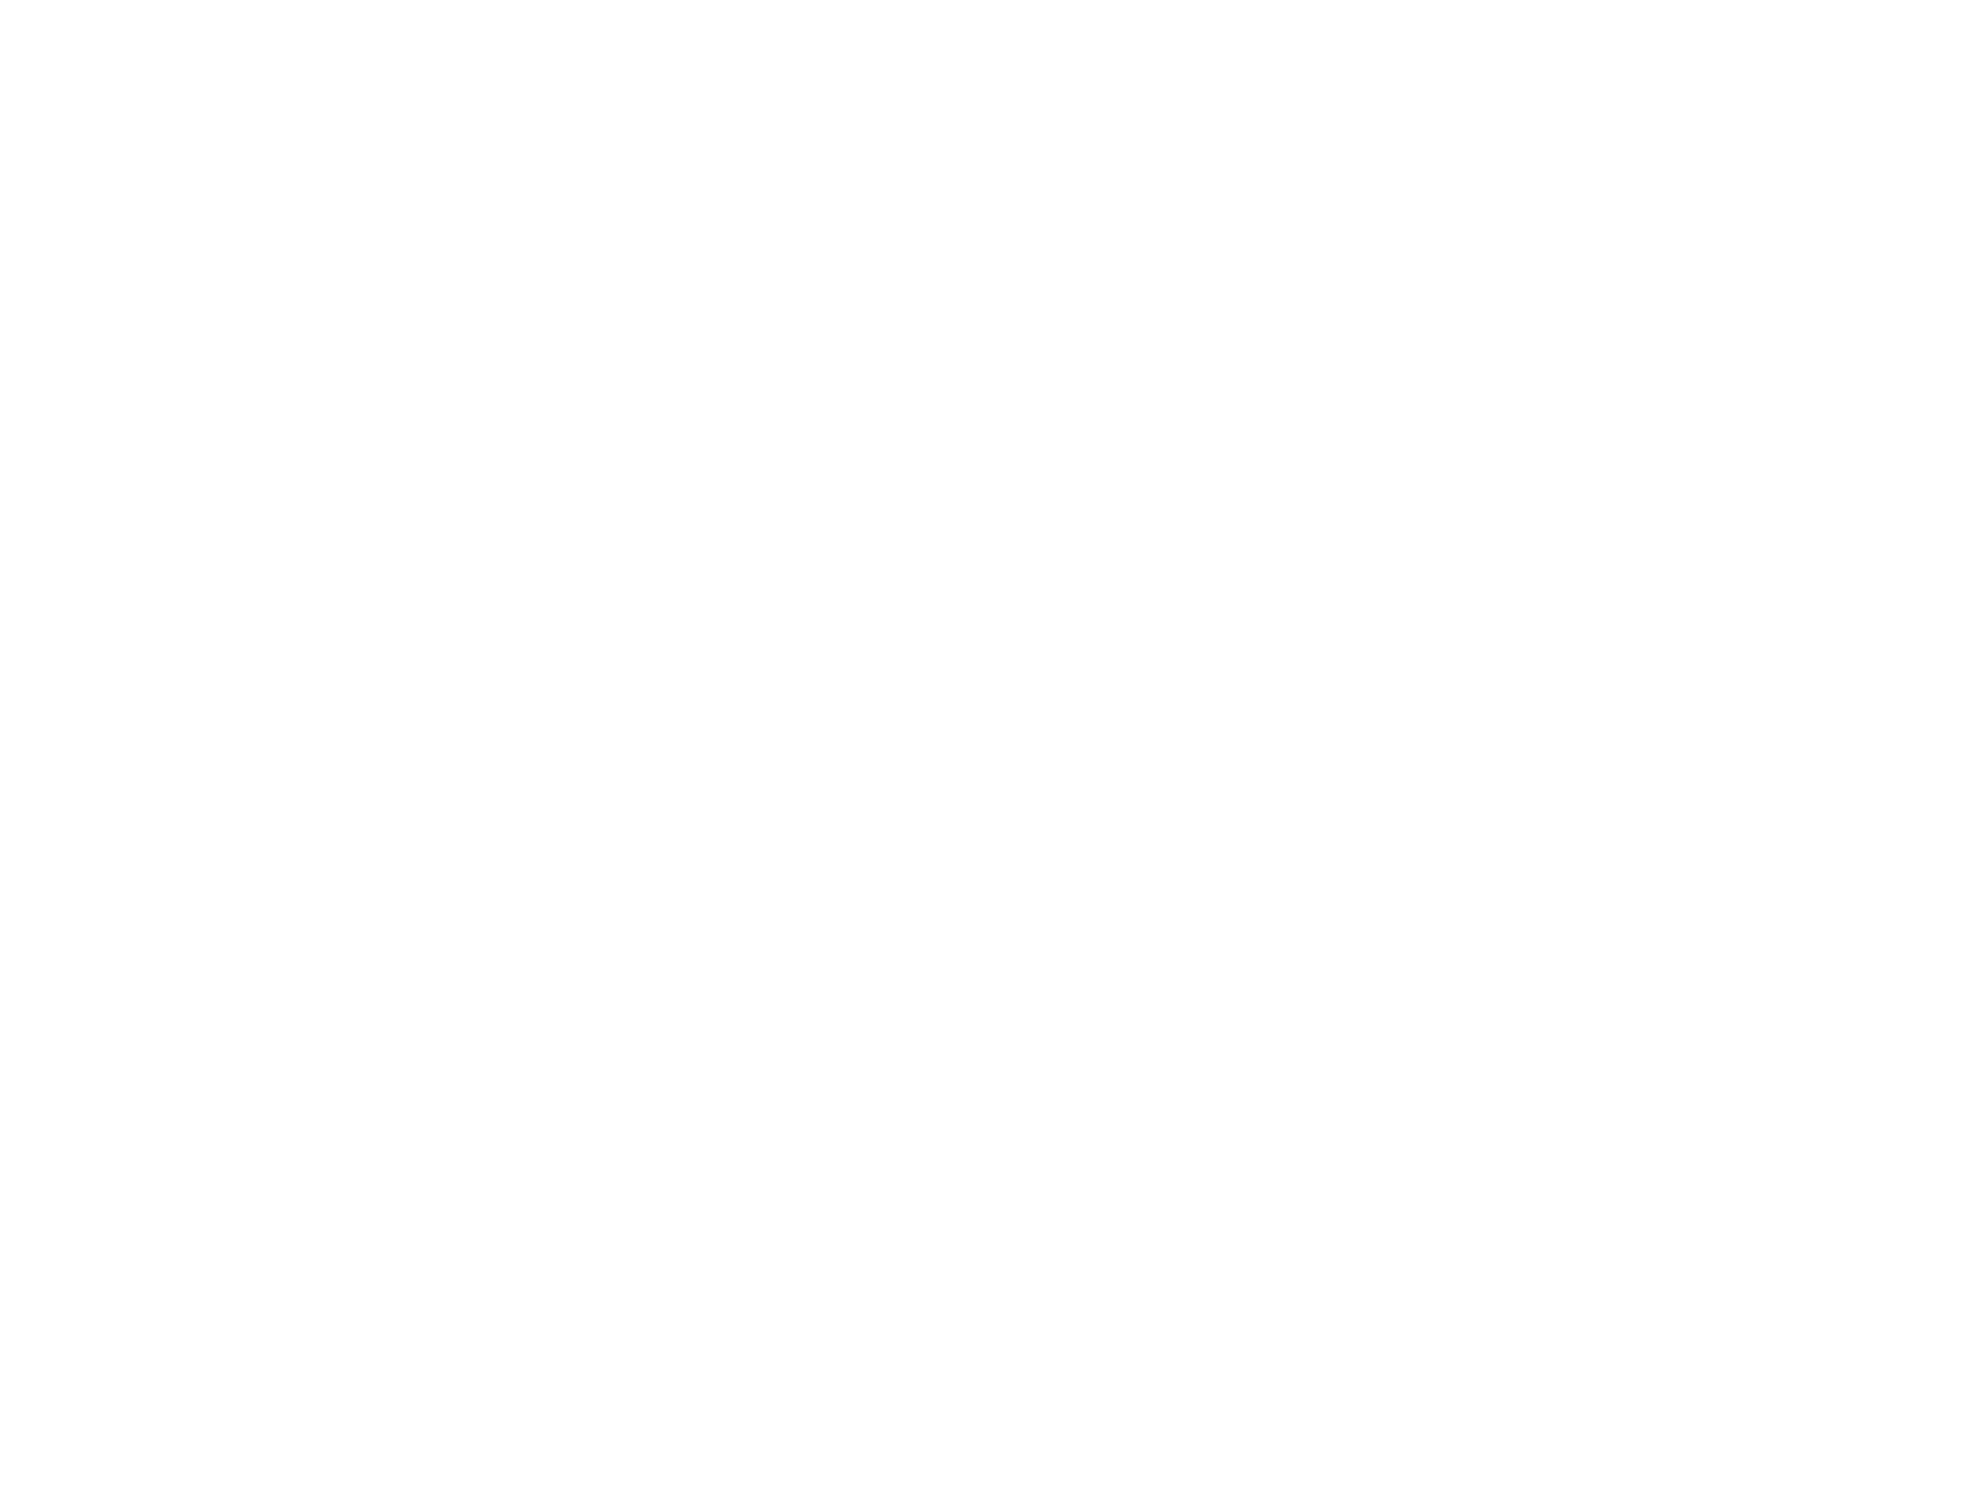


File: Final_Presentation/charts/price_vs_ratings.png
Exists: True
Size: 15139 bytes


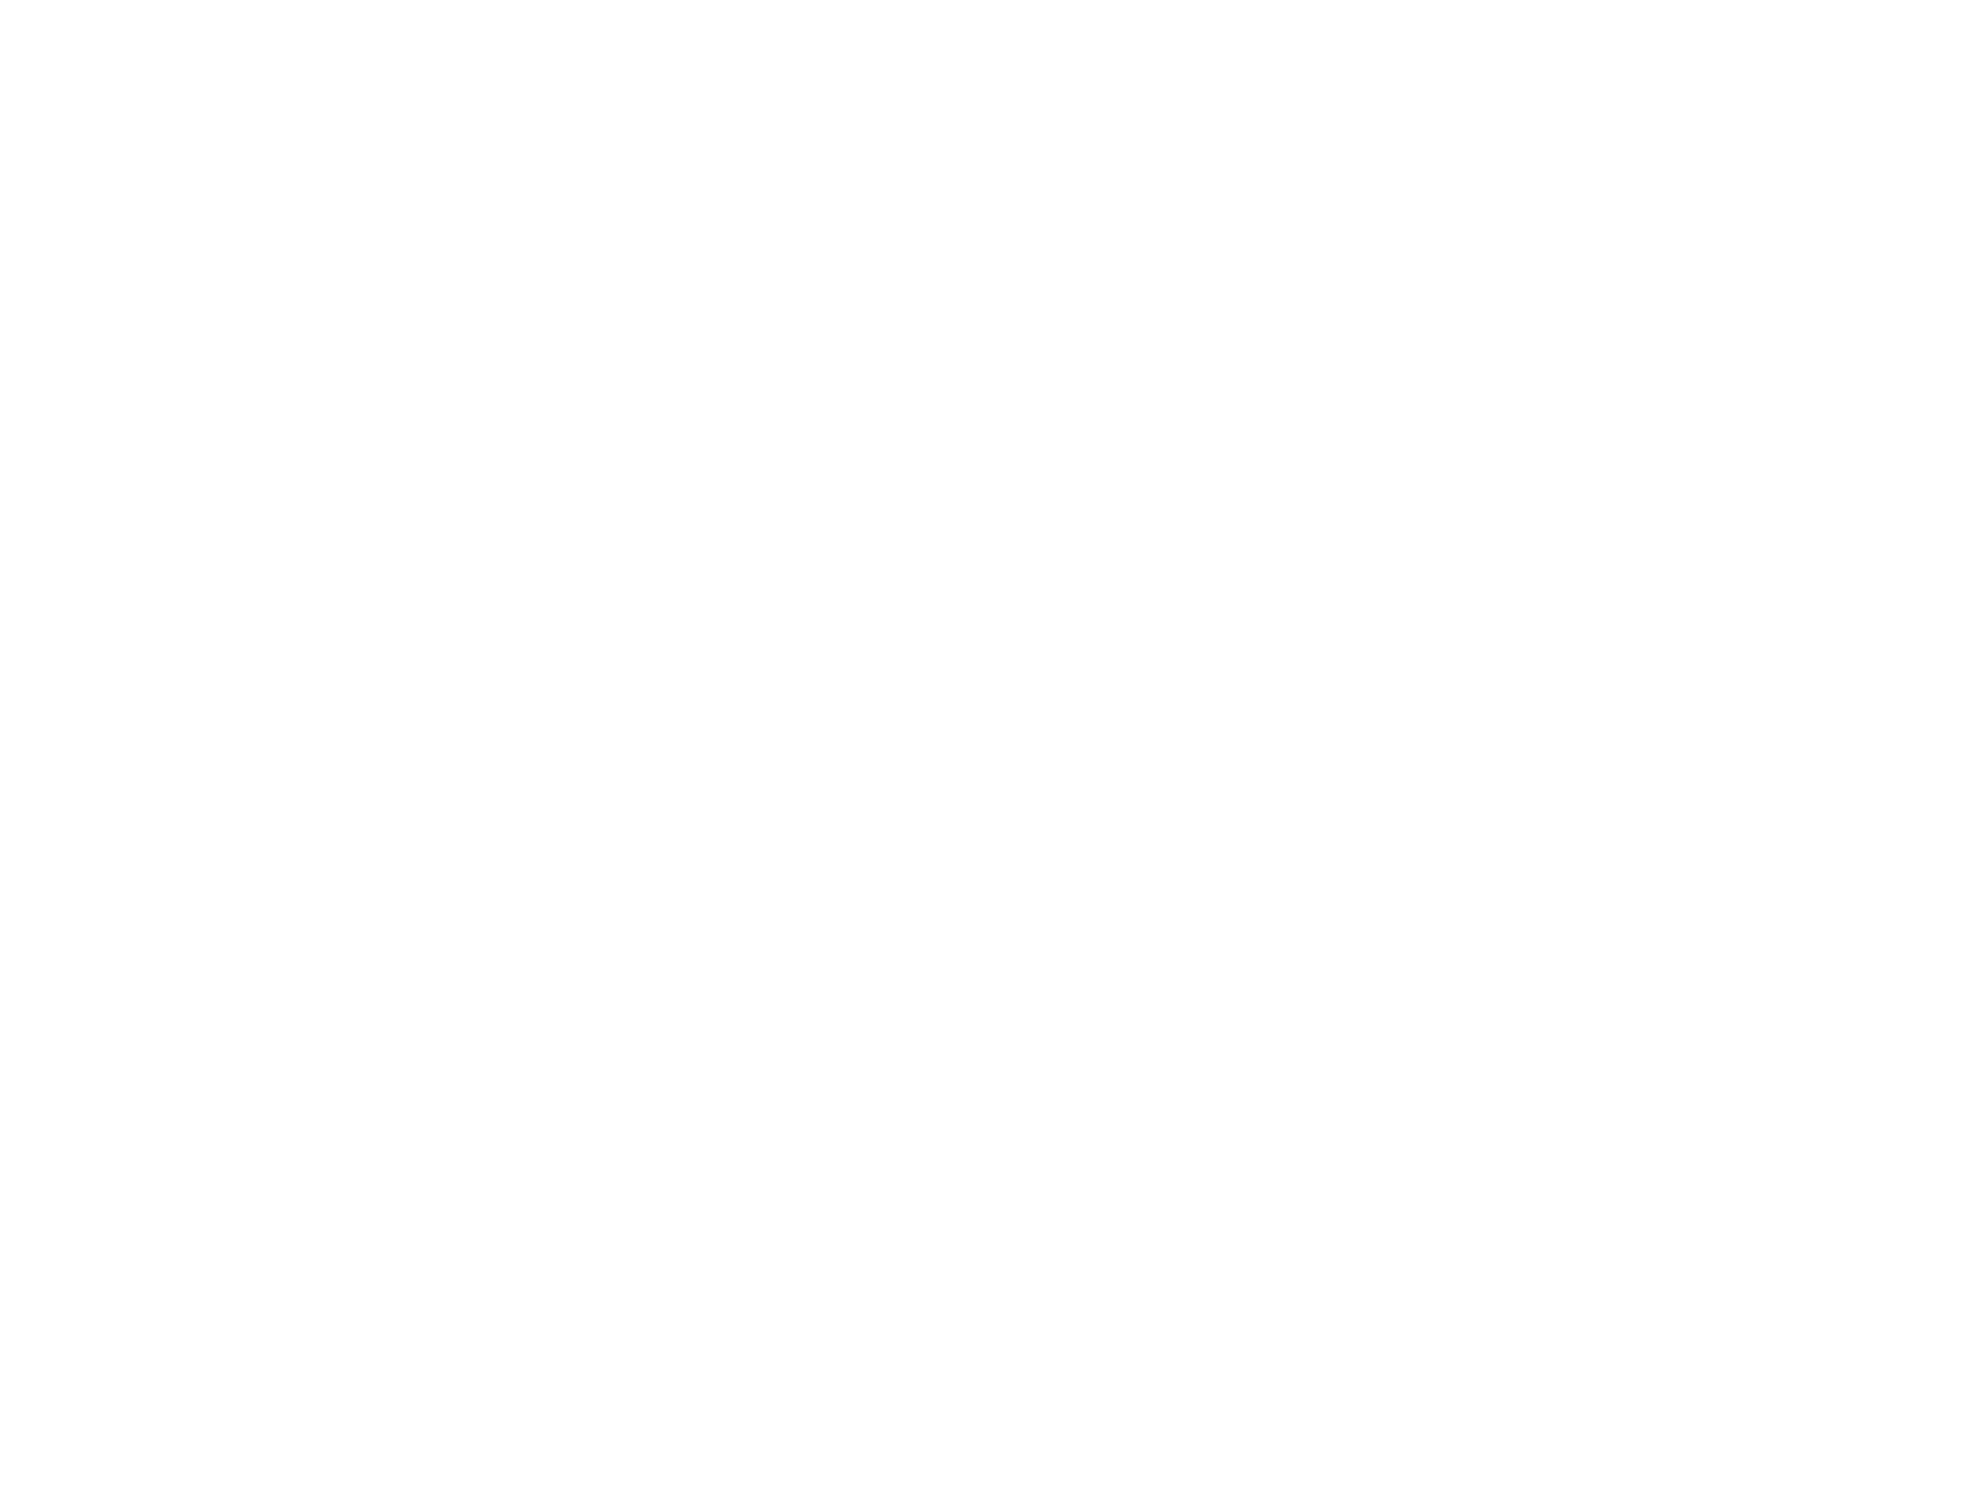

In [30]:
from IPython.display import display, Image
import os

charts = [
    "Final_Presentation/charts/top_10_cuisines.png",
    "Final_Presentation/charts/price_vs_ratings.png"
]

for chart in charts:
    print("\nFile:", chart)
    print("Exists:", os.path.exists(chart))
    print("Size:", os.path.getsize(chart), "bytes")

    display(Image(filename=chart))

In [31]:
print(df.columns.tolist())

['ID\tArea\tCity\tRestaurant\tPrice\tAvg ratings\tTotal ratings\tFood type\tAddress\tDelivery time']


In [33]:
import pandas as pd

df = pd.read_csv(
    "Swiggy_Chennai.csv",
    sep="\t"
)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (1106, 10)

Columns:
['ID', 'Area', 'City', 'Restaurant', 'Price', 'Avg ratings', 'Total ratings', 'Food type', 'Address', 'Delivery time']


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,6345,Teynampet,Chennai,Amaravathi,650,4.2,100,"Indian,Chinese,Andhra,Tandoor",Cathedral Road,53
1,6358,Nandanam,Chennai,Eatalica,500,4.5,100,"Italian,American",Ra Puram,69
2,7776,Gopalapuram,Chennai,The Kati Roll Shop,250,4.3,1000,Street Food,Cathedral Road,52
3,7826,Alwarpet,Chennai,Benjarong,1500,4.6,100,Thai,Ttk Road,68
4,7828,Mylapore,Chennai,Kaaraikudi,500,3.6,100,Chettinad,Dr Radhakrishnan Salai,57


In [35]:

import pandas as pd

# Load the tab-separated CSV file
df = pd.read_csv("Swiggy_Chennai.csv", sep="\t")

# Clean column names
df.columns = df.columns.str.strip()

# Check dataset
print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())


Dataset loaded successfully!
Total rows: 1106
Total columns: 10

Column names:
['ID', 'Area', 'City', 'Restaurant', 'Price', 'Avg ratings', 'Total ratings', 'Food type', 'Address', 'Delivery time']

First 5 records:


,ID,Area,City,Restaurant,Price,Avg ratings,Total ratings,Food type,Address,Delivery time
0,6345,Teynampet,Chennai,Amaravathi,650,4.2,100,"Indian,Chinese,Andhra,Tandoor",Cathedral Road,53
1,6358,Nandanam,Chennai,Eatalica,500,4.5,100,"Italian,American",Ra Puram,69
2,7776,Gopalapuram,Chennai,The Kati Roll Shop,250,4.3,1000,Street Food,Cathedral Road,52
3,7826,Alwarpet,Chennai,Benjarong,1500,4.6,100,Thai,Ttk Road,68
4,7828,Mylapore,Chennai,Kaaraikudi,500,3.6,100,Chettinad,Dr Radhakrishnan Salai,57


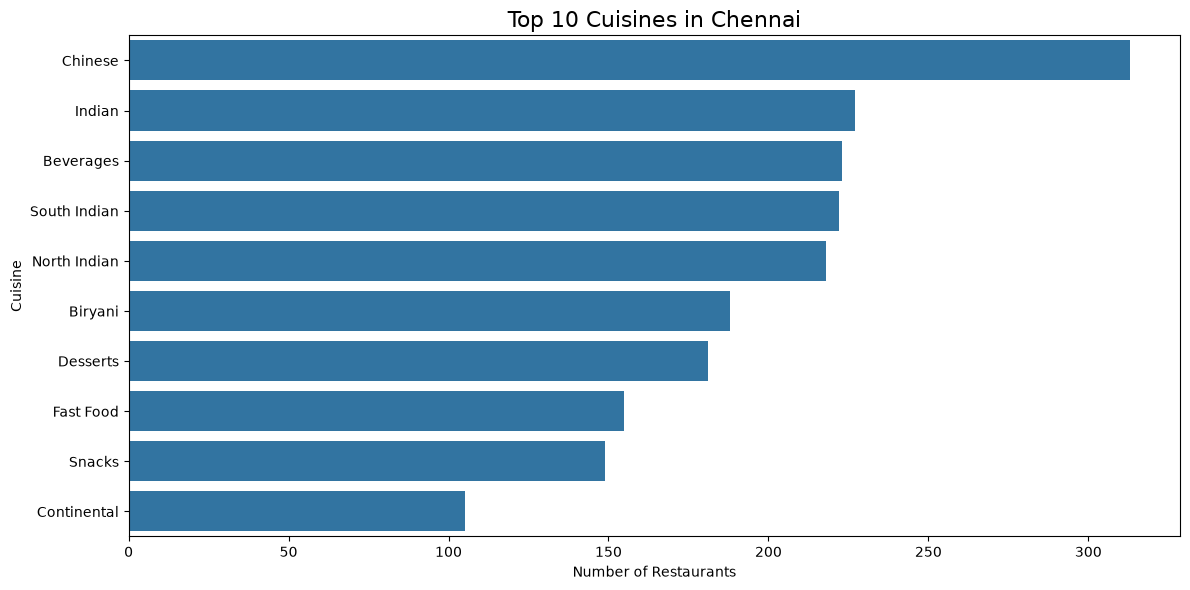

Top 10 Cuisines chart generated successfully!


In [36]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create chart folder if it doesn't exist
os.makedirs("Final_Presentation/charts", exist_ok=True)

# Count restaurants by food type
cuisine_counts = (
    df["Food type"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

# Generate chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=cuisine_counts.values,
    y=cuisine_counts.index
)

plt.title("Top 10 Cuisines in Chennai", fontsize=16)
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.tight_layout()

# Save chart
plt.savefig(
    "Final_Presentation/charts/top_10_cuisines.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Top 10 Cuisines chart generated successfully!")



Chart: top_10_cuisines.png
File size: 101073 bytes


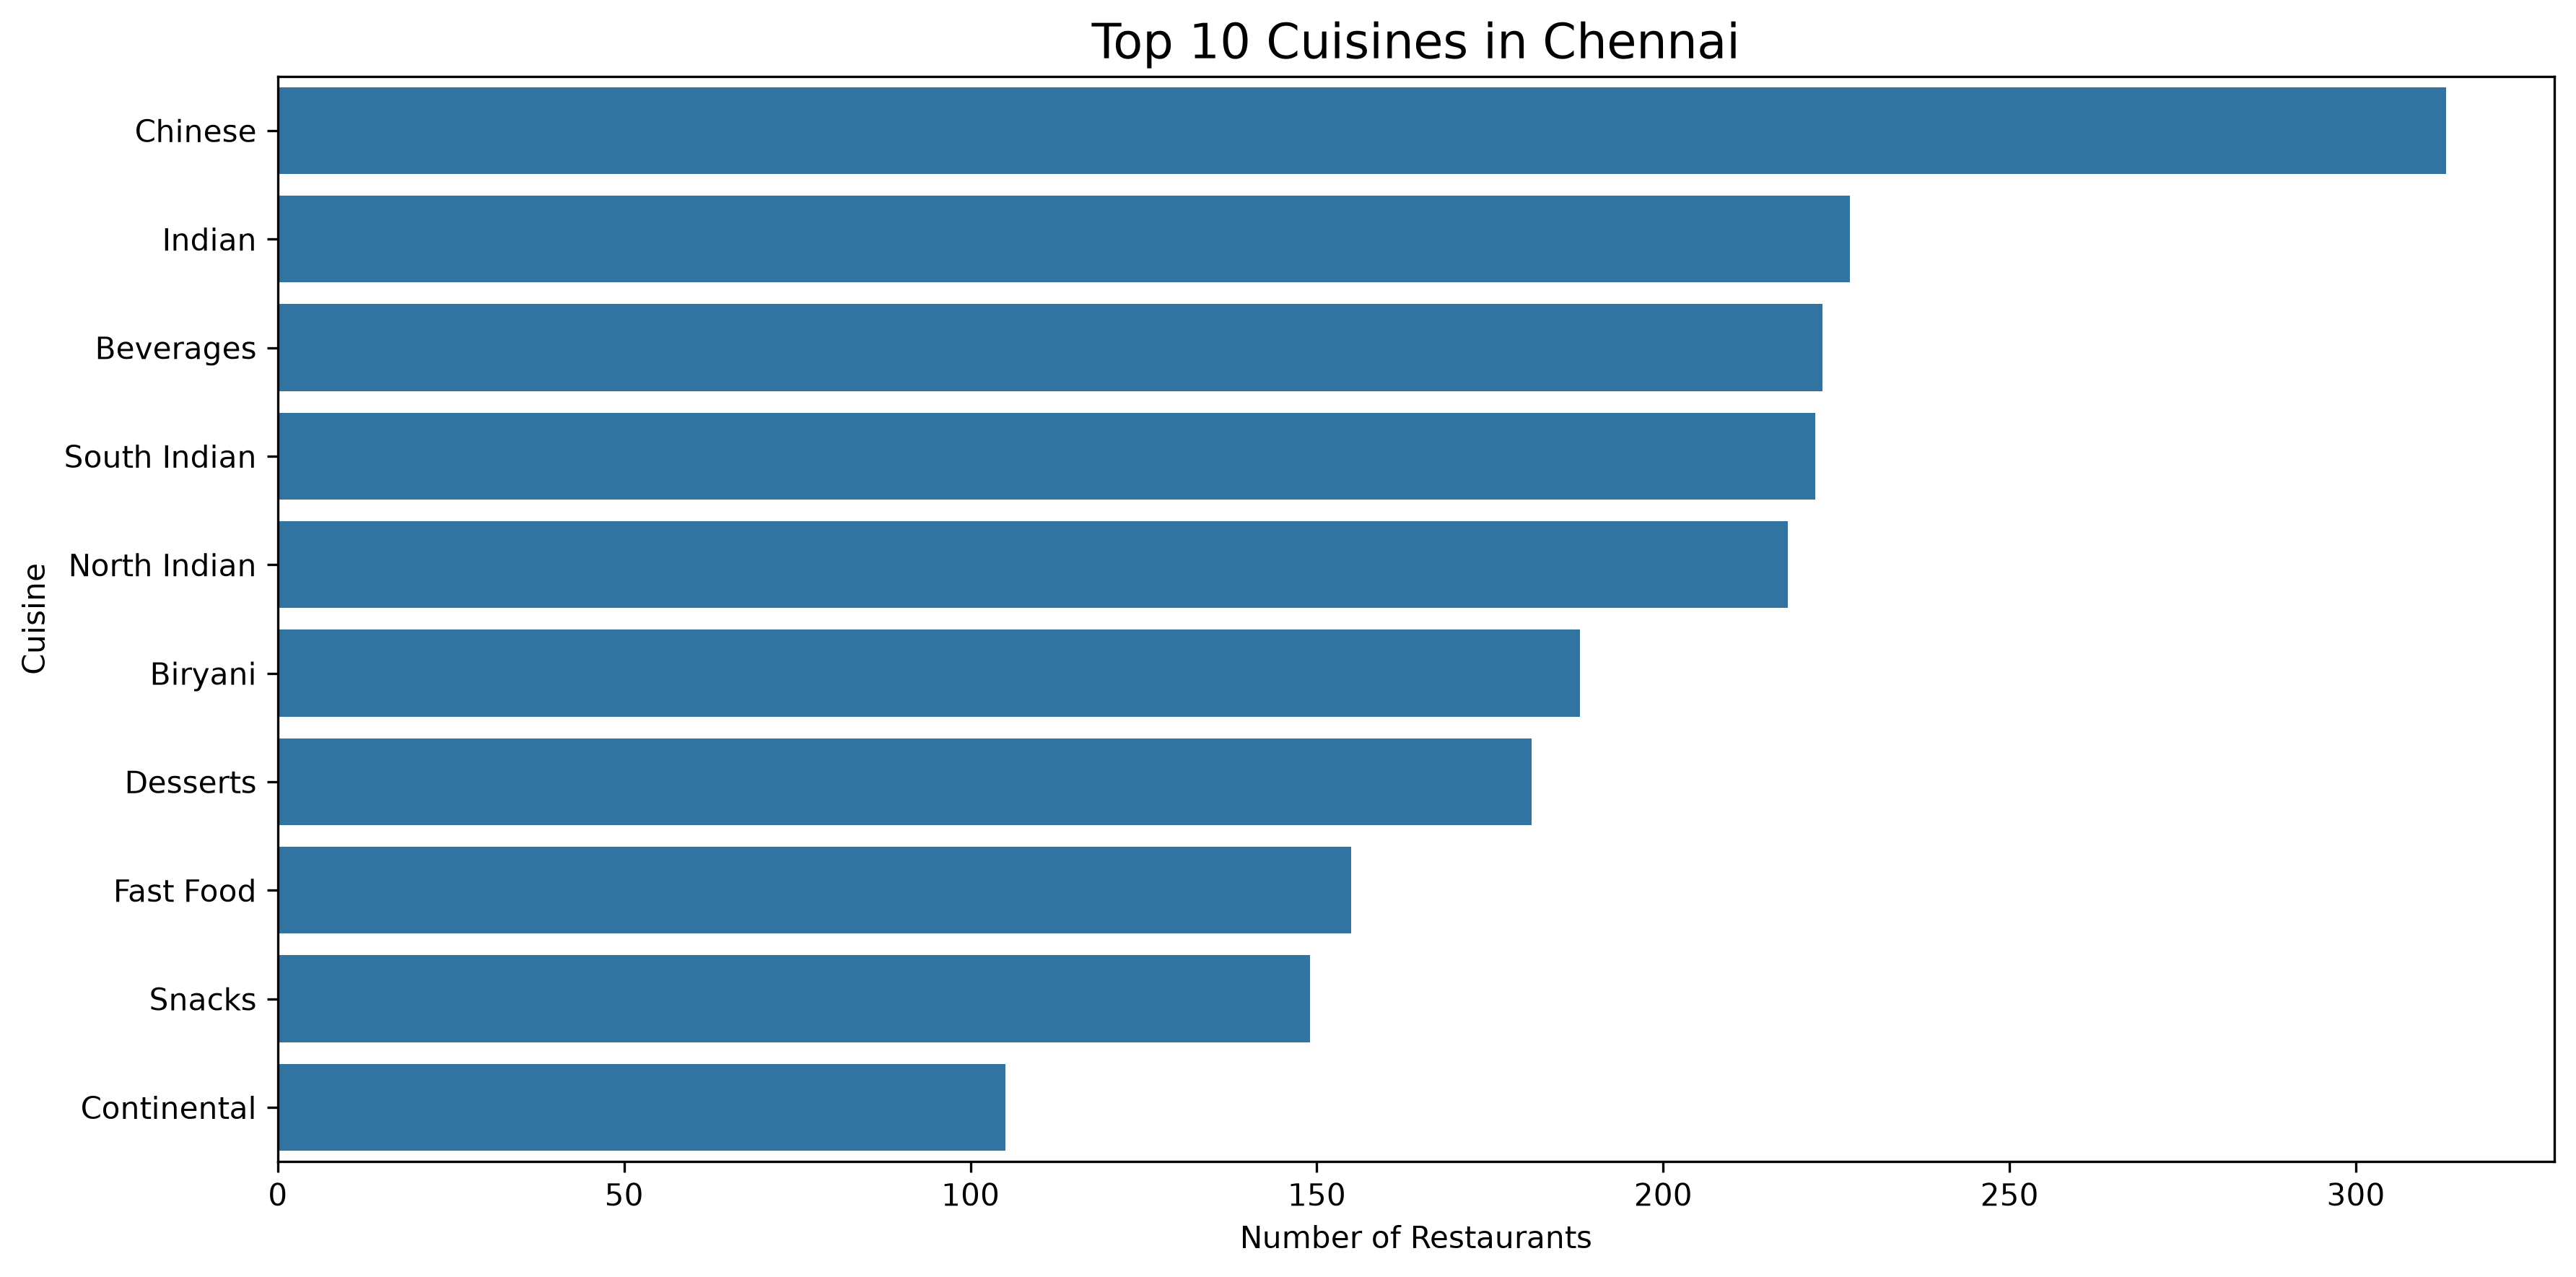


Chart: price_vs_ratings.png
File size: 15139 bytes


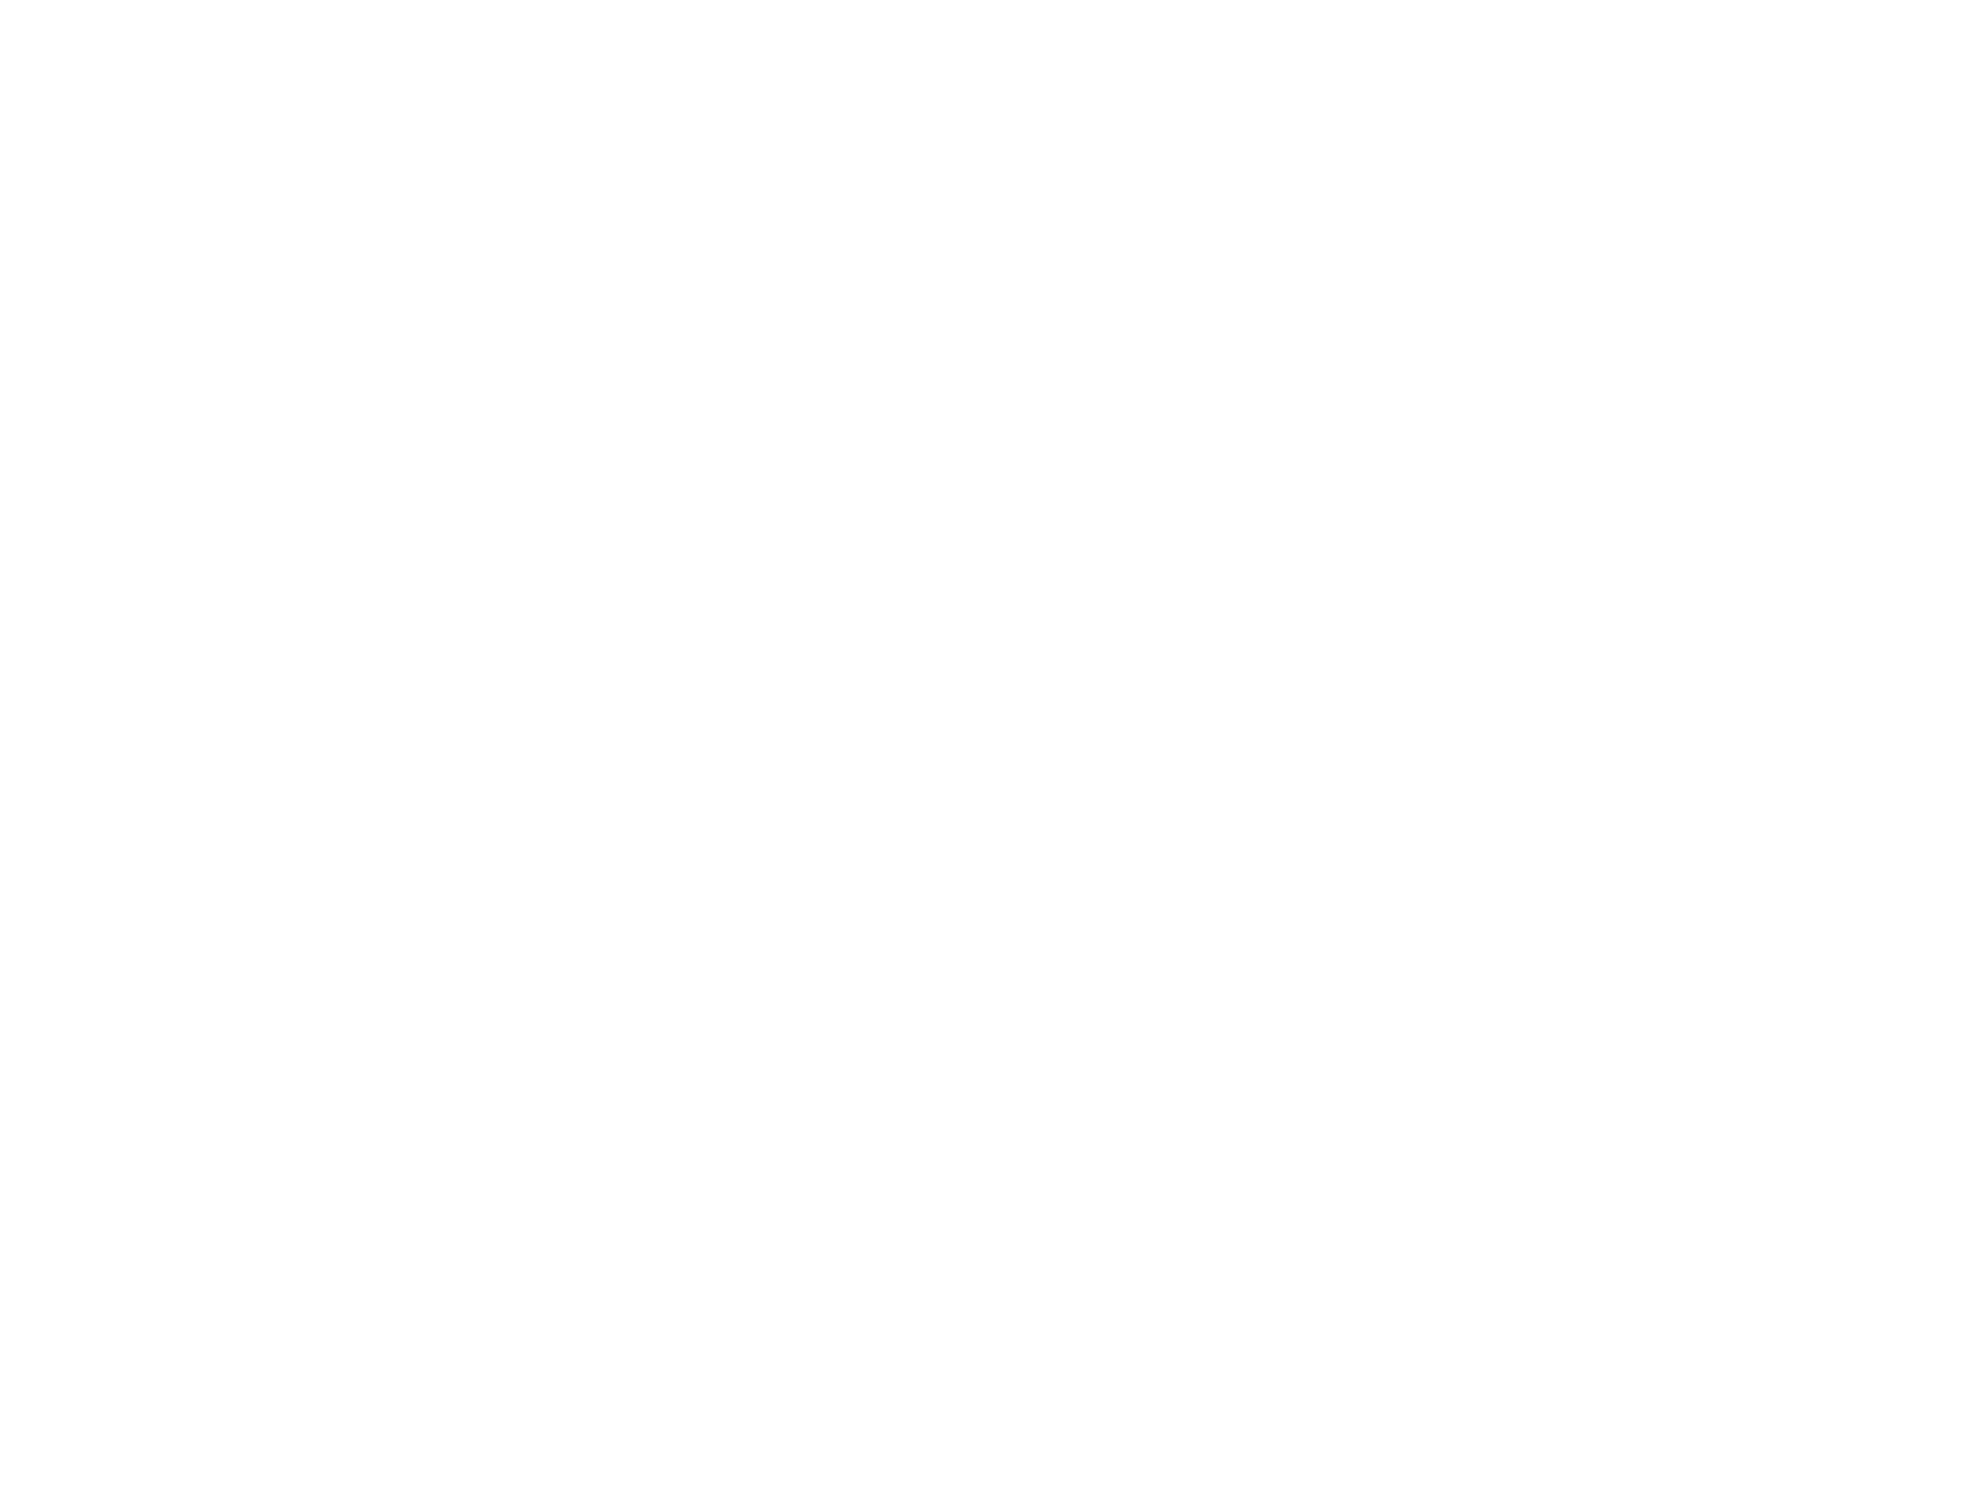

In [37]:
from IPython.display import display, Image
import os

charts = [
    "Final_Presentation/charts/top_10_cuisines.png",
    "Final_Presentation/charts/price_vs_ratings.png"
]

for chart in charts:
    print("\nChart:", os.path.basename(chart))
    print("File size:", os.path.getsize(chart), "bytes")
    display(Image(filename=chart))

In [38]:

print("PRICE COLUMN")
print(df["Price"].head(15))
print("\nPrice data type:", df["Price"].dtype)
print("Valid price values:", df["Price"].notna().sum())

print("\nAVERAGE RATINGS COLUMN")
print(df["Avg ratings"].head(15))
print("\nRatings data type:", df["Avg ratings"].dtype)
print("Valid rating values:", df["Avg ratings"].notna().sum())

print("\nNUMERIC DATA CHECK")
print(df[["Price", "Avg ratings"]].describe())


PRICE COLUMN
0      650
1      500
2      250
3     1500
4      500
5     1100
6      500
7      350
8      500
9      500
10     250
11    1400
12     700
13     800
14    1200
Name: Price, dtype: int64

Price data type: int64
Valid price values: 1106

AVERAGE RATINGS COLUMN
0     4.2
1     4.5
2     4.3
3     4.6
4     3.6
5     4.4
6     4.1
7     4.2
8     4.0
9     4.4
10    4.7
11    4.4
12    4.3
13    3.9
14    4.1
Name: Avg ratings, dtype: float64

Ratings data type: float64
Valid rating values: 1106

NUMERIC DATA CHECK
             Price  Avg ratings
count  1106.000000  1106.000000
mean    356.247740     3.776311
std     262.574015     0.643758
min       0.000000     2.700000
25%     200.000000     2.900000
50%     300.000000     4.000000
75%     400.000000     4.300000
max    2500.000000     5.000000


In [39]:
print("Price sample values:")
print(df["Price"].unique()[:20])

print("\nRating sample values:")
print(df["Avg ratings"].unique()[:20])

print("\nMissing prices:", df["Price"].isna().sum())
print("Missing ratings:", df["Avg ratings"].isna().sum())

Price sample values:
[ 650  500  250 1500 1100  350 1400  700  800 1200  900  600  200 1000
  400  300  850  450  150  100]

Rating sample values:
[4.2 4.5 4.3 4.6 3.6 4.4 4.1 4.  4.7 3.9 3.5 3.8 2.9 3.2 3.7 3.4 3.1 2.7
 4.9 2.8]

Missing prices: 0
Missing ratings: 0


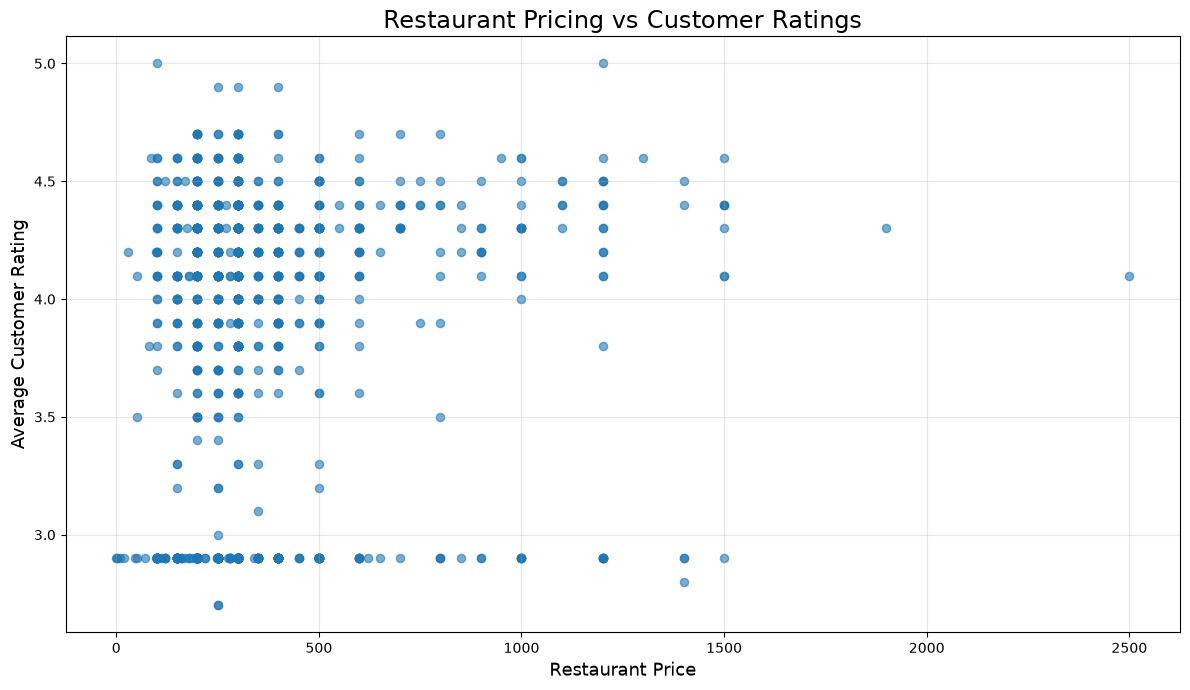

Pricing chart regenerated!
File size: 219385 bytes


In [41]:

import matplotlib.pyplot as plt
import os

# Create a fresh figure
fig, ax = plt.subplots(figsize=(12, 7))

# Plot restaurant price against average ratings
ax.scatter(
    df["Price"],
    df["Avg ratings"],
    alpha=0.6,
    s=35
)

# Add titles and labels
ax.set_title("Restaurant Pricing vs Customer Ratings", fontsize=17)
ax.set_xlabel("Restaurant Price", fontsize=13)
ax.set_ylabel("Average Customer Rating", fontsize=13)

ax.grid(True, alpha=0.3)

plt.tight_layout()

# Save the chart
chart_path = "Final_Presentation/charts/price_vs_ratings.png"

fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Pricing chart regenerated!")
print("File size:", os.path.getsize(chart_path), "bytes")


In [42]:

from pptx import Presentation
from pptx.util import Inches

# Reopen the existing presentation
prs = Presentation(output_path)

# Replace chart on Slide 6 (Top 10 Cuisines)
slide6 = prs.slides[5]

for shape in list(slide6.shapes):
    if shape.shape_type == 13:
        element = shape._element
        element.getparent().remove(element)

slide6.shapes.add_picture(
    "Final_Presentation/charts/top_10_cuisines.png",
    Inches(1.0), Inches(1.3),
    width=Inches(11.3),
    height=Inches(5.5)
)

# Replace chart on Slide 7 (Pricing Analysis)
slide7 = prs.slides[6]

for shape in list(slide7.shapes):
    if shape.shape_type == 13:
        element = shape._element
        element.getparent().remove(element)

slide7.shapes.add_picture(
    "Final_Presentation/charts/price_vs_ratings.png",
    Inches(2.0), Inches(1.2),
    width=Inches(9.3),
    height=Inches(5.4)
)

# Save the updated presentation
prs.save(output_path)

print("Slides 6 and 7 updated successfully!")
print("Presentation saved:", output_path)


PackageNotFoundError: Package not found at 'Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx'

In [43]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nChecking presentation path:")

ppt_path = "Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx"

print("File exists:", os.path.exists(ppt_path))

print("\nPowerPoint files found:")

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".pptx"):
            print(os.path.join(root, file))

Current working directory:
c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai

Checking presentation path:
File exists: True

PowerPoint files found:
.\Final_Presentation\Urban_Food_Delivery_Analysis_Final.pptx


In [44]:

from pptx import Presentation
from pptx.util import Inches
import os

# Use the verified exact path
output_path = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx"
)

# Check file
print("File exists:", os.path.exists(output_path))
print("File size:", os.path.getsize(output_path))

# Open presentation
prs = Presentation(output_path)

print("Slides found:", len(prs.slides))

# Update Slide 6 - Top 10 Cuisines
slide6 = prs.slides[5]

for shape in list(slide6.shapes):
    if shape.shape_type == 13:
        shape._element.getparent().remove(shape._element)

slide6.shapes.add_picture(
    "Final_Presentation/charts/top_10_cuisines.png",
    Inches(1.0), Inches(1.3),
    width=Inches(11.3),
    height=Inches(5.5)
)

# Update Slide 7 - Pricing Analysis
slide7 = prs.slides[6]

for shape in list(slide7.shapes):
    if shape.shape_type == 13:
        shape._element.getparent().remove(shape._element)

slide7.shapes.add_picture(
    "Final_Presentation/charts/price_vs_ratings.png",
    Inches(2.0), Inches(1.2),
    width=Inches(9.3),
    height=Inches(5.4)
)

# Save updated PowerPoint
prs.save(output_path)

print("\nSlides 6 and 7 updated successfully!")
print("PowerPoint saved successfully!")


File exists: True
File size: 459714


PackageNotFoundError: Package not found at 'c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Final_Presentation\Urban_Food_Delivery_Analysis_Final.pptx'

In [46]:

import os
import zipfile

ppt_path = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx"
)

print("File path:", ppt_path)
print("File exists:", os.path.exists(ppt_path))
print("File size:", os.path.getsize(ppt_path), "bytes")

print("\nIs it a valid ZIP/PPTX package?")
print(zipfile.is_zipfile(ppt_path))

print("\nChecking backup PowerPoint files:")

for root, dirs, files in os.walk("Final_Presentation"):
    for file in files:
        if file.endswith(".pptx"):
            path = os.path.join(root, file)
            print(file, "|", os.path.getsize(path), "bytes",
                  "| Valid ZIP:", zipfile.is_zipfile(path))


File path: c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Final_Presentation\Urban_Food_Delivery_Analysis_Final.pptx
File exists: True
File size: 459714 bytes

Is it a valid ZIP/PPTX package?
False

Checking backup PowerPoint files:
Urban_Food_Delivery_Analysis_Final.pptx | 459714 bytes | Valid ZIP: False


In [47]:

import os
import zipfile

search_folder = r"C:\Users\kames\OneDrive\Desktop\Data Analytics"

print("Searching for PowerPoint files...\n")

for root, dirs, files in os.walk(search_folder):
    for file in files:
        if file.lower().endswith(".pptx"):
            path = os.path.join(root, file)
            size = os.path.getsize(path)
            valid = zipfile.is_zipfile(path)

            print("File:", path)
            print("Size:", size, "bytes")
            print("Valid PowerPoint package:", valid)
            print("-" * 50)

print("\nOriginal file signature:")
with open(ppt_path, "rb") as f:
    print(f.read(30))


Searching for PowerPoint files...

File: C:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Final_Presentation\Urban_Food_Delivery_Analysis_Final.pptx
Size: 459714 bytes
Valid PowerPoint package: False
--------------------------------------------------
File: C:\Users\kames\OneDrive\Desktop\Data Analytics\venv\Lib\site-packages\pptx\templates\default.pptx
Size: 34030 bytes
Valid PowerPoint package: True
--------------------------------------------------

Original file signature:


PermissionError: [Errno 13] Permission denied: 'c:\\Users\\kames\\OneDrive\\Desktop\\Data Analytics\\Swiggy Chennai\\Final_Presentation\\Urban_Food_Delivery_Analysis_Final.pptx'

In [48]:

import os

ppt_path = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx"
)

print("File exists:", os.path.exists(ppt_path))

try:
    with open(ppt_path, "rb") as f:
        signature = f.read(30)

    print("File is readable!")
    print("File signature:", signature)

except PermissionError:
    print("File is still locked. Check PowerPoint and OneDrive.")

except Exception as e:
    print("Error:", e)


File exists: True
File is still locked. Check PowerPoint and OneDrive.


In [49]:

import os
import shutil

source = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Final.pptx"
)

backup = os.path.abspath(
    "Final_Presentation/Recovery_Copy.pptx"
)

try:
    shutil.copy2(source, backup)
    print("Recovery copy created!")
    print("Location:", backup)
    print("File size:", os.path.getsize(backup))
    
except Exception as e:
    print("Copy failed:", e)


Recovery copy created!
Location: c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Final_Presentation\Recovery_Copy.pptx
File size: 459714


In [50]:

import zipfile
import os

print("Recovery copy exists:", os.path.exists(backup))
print("Valid ZIP package:", zipfile.is_zipfile(backup))

with open(backup, "rb") as f:
    signature = f.read(30)

print("File signature:", signature)


Recovery copy exists: True
Valid ZIP package: True
File signature: b'PK\x03\x04\x14\x00\x00\x00\x08\x00\x05Px]\xce*\x90=\xf1\x01\x00\x00\x02\x12\x00\x00\x13\x00\x00\x00'


In [51]:

from pptx import Presentation

recovered_prs = Presentation(backup)

print("Recovery copy opened successfully!")
print("Total slides:", len(recovered_prs.slides))

for i, slide in enumerate(recovered_prs.slides, start=1):
    pictures = sum(
        1 for shape in slide.shapes
        if shape.shape_type == 13
    )
    print(f"Slide {i}: {pictures} images")


Recovery copy opened successfully!
Total slides: 11
Slide 1: 0 images
Slide 2: 0 images
Slide 3: 0 images
Slide 4: 0 images
Slide 5: 0 images
Slide 6: 0 images
Slide 7: 1 images
Slide 8: 1 images
Slide 9: 1 images
Slide 10: 2 images
Slide 11: 0 images


In [52]:

for i, slide in enumerate(recovered_prs.slides, start=1):
    print(f"\n--- SLIDE {i} ---")

    for shape in slide.shapes:
        if shape.has_text_frame and shape.text.strip():
            print(shape.text.strip().replace("\n", " | "))



--- SLIDE 1 ---
URBAN FOOD DELIVERY
ANALYSIS – CHENNAI
Exploring restaurant trends, pricing, ratings and delivery patterns
PYTHON  |  PANDAS  |  MATPLOTLIB  |  SEABORN

--- SLIDE 2 ---
PROJECT OVERVIEW
This project explores the urban food delivery ecosystem in Chennai using restaurant-level data and Python.
• Analyze popular cuisines and restaurant competition | • Understand restaurant pricing patterns | • Explore customer ratings and delivery trends | • Identify neighborhood-level restaurant distribution | • Generate actionable business insights

--- SLIDE 3 ---
DATASET OVERVIEW

--- SLIDE 4 ---
DATASET OVERVIEW
TOTAL RECORDS | 958
TOTAL COLUMNS | 1
DATA FORMAT | CSV
ANALYSIS TOOL | Python
The dataset contains restaurant-level information from Chennai, covering cuisines, pricing, customer ratings, online ordering and location-based restaurant distribution.

--- SLIDE 5 ---
DATA CLEANING & PREPROCESSING
01     Missing Values  |  Identified and examined missing data
02     Duplicate Re

In [53]:

slide3 = recovered_prs.slides[2]

print("Slide 3 shape count:", len(slide3.shapes))

for shape in slide3.shapes:
    print(
        "Shape type:", shape.shape_type,
        "| Text:", shape.text[:100] if shape.has_text_frame else "No text"
    )


Slide 3 shape count: 1
Shape type: TEXT_BOX (17) | Text: DATASET OVERVIEW


In [54]:
for shape in recovered_prs.slides[2].shapes:
    print("Text:", shape.text)
    print("Position:", shape.left, shape.top)
    print("Width:", shape.width)
    print("Height:", shape.height)

Text: DATASET OVERVIEW
Position: 640080 457200
Width: 10972800
Height: 731520


In [55]:
import shutil
import os

working_path = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Recovered.pptx"
)

shutil.copy2(backup, working_path)

print("Working copy created:", os.path.exists(working_path))
print("Location:", working_path)

Working copy created: True
Location: c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Final_Presentation\Urban_Food_Delivery_Analysis_Recovered.pptx


In [56]:
from pptx import Presentation

recovered_prs = Presentation(working_path)

# Remove duplicate Slide 3
slide_id_list = recovered_prs.slides._sldIdLst
slide_to_remove = slide_id_list[2]

slide_id_list.remove(slide_to_remove)

# Save working presentation
recovered_prs.save(working_path)

print("Duplicate slide removed successfully!")
print("Remaining slides:", len(recovered_prs.slides))

Duplicate slide removed successfully!
Remaining slides: 10


In [57]:
for i, slide in enumerate(recovered_prs.slides, start=1):
    texts = [
        shape.text.strip().replace("\n", " | ")
        for shape in slide.shapes
        if shape.has_text_frame and shape.text.strip()
    ]

    print(f"Slide {i}:", texts[:2])

Slide 1: ['URBAN FOOD DELIVERY', 'ANALYSIS – CHENNAI']
Slide 2: ['PROJECT OVERVIEW', 'This project explores the urban food delivery ecosystem in Chennai using restaurant-level data and Python.']
Slide 3: ['DATASET OVERVIEW', 'TOTAL RECORDS | 958']
Slide 4: ['DATA CLEANING & PREPROCESSING', '01     Missing Values  |  Identified and examined missing data']
Slide 5: ['EXPLORATORY DATA ANALYSIS', '01  |  Cuisine Analysis | Popular cuisines and restaurant competition']
Slide 6: ['TOP 10 CUISINES IN CHENNAI']
Slide 7: ['RESTAURANT PRICING ANALYSIS', 'Analyzing the relationship between restaurant pricing and customer ratings.']
Slide 8: ['ONLINE ORDERING & CUSTOMER RATINGS']
Slide 9: ['RESTAURANT COMPETITION & NEIGHBORHOOD ANALYSIS', 'CUISINE COMPETITION']
Slide 10: ['KEY INSIGHTS & CONCLUSION', '• Identified popular cuisines and restaurant competition. | • Explored restaurant pricing and customer rating patterns. | • Analyzed online ordering and customer ratings. | • Examined restaurant dist

In [58]:

from pptx import Presentation

recovered_prs = Presentation(working_path)

slide3 = recovered_prs.slides[2]

for shape in slide3.shapes:
    if shape.has_text_frame:
        text = shape.text

        if "TOTAL RECORDS" in text:
            shape.text = "TOTAL RECORDS | 1,106"

        elif "TOTAL COLUMNS" in text:
            shape.text = "TOTAL COLUMNS | 10"

recovered_prs.save(working_path)

print("Dataset Overview updated!")
print("Records: 1,106")
print("Columns: 10")


Dataset Overview updated!
Records: 1,106
Columns: 10


C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\zipfile\__init__.py:1661: UserWarning: Duplicate name: 'ppt/slides/slide3.xml'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\zipfile\__init__.py:1661: UserWarning: Duplicate name: 'ppt/slides/_rels/slide3.xml.rels'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


In [59]:

import zipfile
from pptx import Presentation

print("Checking ZIP integrity...")

with zipfile.ZipFile(working_path, "r") as z:
    print("ZIP test result:", z.testzip())

    names = z.namelist()
    duplicates = sorted({
        name for name in names
        if names.count(name) > 1
    })

    print("\nDuplicate files:", duplicates)

print("\nChecking PowerPoint readability...")

try:
    test_prs = Presentation(working_path)
    print("PowerPoint opens successfully!")
    print("Total slides:", len(test_prs.slides))
except Exception as e:
    print("PowerPoint validation failed:", e)


Checking ZIP integrity...
ZIP test result: None

Duplicate files: ['ppt/slides/_rels/slide3.xml.rels', 'ppt/slides/slide3.xml']

Checking PowerPoint readability...
PowerPoint opens successfully!
Total slides: 10


In [60]:

import zipfile
import os

clean_path = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Clean.pptx"
)

with zipfile.ZipFile(working_path, "r") as source:
    latest_entries = {}

    # Keep the latest version of each file
    for info in source.infolist():
        latest_entries[info.filename] = info

    with zipfile.ZipFile(clean_path, "w", zipfile.ZIP_DEFLATED) as target:
        for filename, info in latest_entries.items():
            target.writestr(info, source.read(info))

print("Clean presentation created!")
print("File size:", os.path.getsize(clean_path))
print("Valid ZIP:", zipfile.is_zipfile(clean_path))

with zipfile.ZipFile(clean_path, "r") as z:
    print("ZIP integrity:", z.testzip())
    print("Duplicate entries:", len(z.namelist()) - len(set(z.namelist())))


Clean presentation created!
File size: 458759
Valid ZIP: True
ZIP integrity: None
Duplicate entries: 0


In [61]:
from pptx import Presentation

final_prs = Presentation(clean_path)

print("Clean PowerPoint opened successfully!")
print("Total slides:", len(final_prs.slides))

for i, slide in enumerate(final_prs.slides, start=1):
    images = sum(1 for shape in slide.shapes if shape.shape_type == 13)
    print(f"Slide {i}: {images} images")

Clean PowerPoint opened successfully!
Total slides: 10
Slide 1: 0 images
Slide 2: 0 images
Slide 3: 0 images
Slide 4: 0 images
Slide 5: 0 images
Slide 6: 1 images
Slide 7: 1 images
Slide 8: 1 images
Slide 9: 2 images
Slide 10: 0 images


In [62]:
import shutil
from pptx import Presentation
from pptx.util import Inches
import os

# Create another safe working copy
updated_path = os.path.abspath(
    "Final_Presentation/Urban_Food_Delivery_Analysis_Updated.pptx"
)

shutil.copy2(clean_path, updated_path)

final_prs = Presentation(updated_path)

# Slide 6 - Top 10 Cuisines
slide6 = final_prs.slides[5]

for shape in list(slide6.shapes):
    if shape.shape_type == 13:
        shape._element.getparent().remove(shape._element)

slide6.shapes.add_picture(
    "Final_Presentation/charts/top_10_cuisines.png",
    Inches(1.0), Inches(1.3),
    width=Inches(11.3),
    height=Inches(5.5)
)

# Slide 7 - Restaurant Pricing
slide7 = final_prs.slides[6]

for shape in list(slide7.shapes):
    if shape.shape_type == 13:
        shape._element.getparent().remove(shape._element)

slide7.shapes.add_picture(
    "Final_Presentation/charts/price_vs_ratings.png",
    Inches(2.0), Inches(1.2),
    width=Inches(9.3),
    height=Inches(5.4)
)

final_prs.save(updated_path)

print("Slides 6 and 7 charts replaced successfully!")
print("Updated file:", updated_path)


Slides 6 and 7 charts replaced successfully!
Updated file: c:\Users\kames\OneDrive\Desktop\Data Analytics\Swiggy Chennai\Final_Presentation\Urban_Food_Delivery_Analysis_Updated.pptx


In [63]:

import zipfile
from pptx import Presentation
import os

print("File size:", os.path.getsize(updated_path))

with zipfile.ZipFile(updated_path, "r") as z:
    print("ZIP integrity:", z.testzip())
    print("Valid ZIP:", zipfile.is_zipfile(updated_path))

check_prs = Presentation(updated_path)

print("\nTotal slides:", len(check_prs.slides))

for i, slide in enumerate(check_prs.slides, start=1):
    images = sum(1 for shape in slide.shapes if shape.shape_type == 13)
    print(f"Slide {i}: {images} images")


File size: 708019
ZIP integrity: None
Valid ZIP: True

Total slides: 10
Slide 1: 0 images
Slide 2: 0 images
Slide 3: 0 images
Slide 4: 0 images
Slide 5: 0 images
Slide 6: 1 images
Slide 7: 1 images
Slide 8: 1 images
Slide 9: 2 images
Slide 10: 0 images


In [64]:
import os

os.startfile(os.path.abspath(updated_path))

print("Opening updated PowerPoint...")

Opening updated PowerPoint...
